# Biomedical Disease NER with BioBERT

COMP9444 research notebook

1. Environment and imports
2. NCBI Disease Corpus download
3. Preprocessing and tokenization
4. Standardized typed entity evaluation
5. Fine-tuning experiments
   - E1 head-only baseline with staged hyperparameter searches
   - E2 partial fine-tuning with encoder and head learning-rate searches

Run all cells in order. Only this notebook is required for submission.


## **_1. Introduction and Library Imports_**

这里需要说明问题的定义，包括研究的背景和动机，以及需要解决的问题

最后单独介绍一下引用的库（可以不做）


### Reproducible environment

Run this notebook from top to bottom and save it with its outputs before submission.
This notebook is the only submission file needed: it downloads the NCBI corpus and
BioBERT, prepares all datasets, runs E1 and E2, and displays the final tables and curves.
No project Python scripts or previous experiment results are required.

The code uses Python 3.10 or newer, PyTorch 2.9.0 and Transformers 5.3.0.
The next cell installs missing dependencies into the current kernel.
Internet access and a writable working directory are needed for the first run.
CUDA uses BF16 when supported, SDPA, fused AdamW and TF32 in fast mode.
CPU and MPS use the FP32 fallback. Seeds are recorded, while CUDA fast mode does not
enforce deterministic kernels. Each experiment setup creates a new output directory.
Training progress bars disappear when a stage finishes; tables and plots remain saved
inside the notebook. Set `SMOKE_TEST = True` in Section 5 only for a short pipeline check.


In [1]:
# Install missing dependencies in this kernel; no repository files are required.
import importlib.util
import importlib.metadata
import subprocess
import sys

required_packages = {
    "torch": "torch==2.9.0",
    "transformers": "transformers==5.3.0",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "tqdm": "tqdm",
}
missing_packages = [package for module, package in required_packages.items()
                    if importlib.util.find_spec(module) is None]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])
print("Python:", sys.version.split()[0])
for package in required_packages:
    print(f"{package}: {importlib.metadata.version(package)}")


Python: 3.12.16
torch: 2.9.0+cu128
transformers: 5.3.0
numpy: 2.5.4
pandas: 3.1.1
matplotlib: 3.11.2
tqdm: 4.70.1


In [2]:
# import all the libs here
import numpy as np
import pandas as pd
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import shutil
import torch

print('all the libs are successfully imported')

# Prefer Apple Metal (MPS), then NVIDIA CUDA, and fall back to CPU.
def select_device():
    mps_backend = getattr(torch.backends, "mps", None)
    if mps_backend is not None and mps_backend.is_available():
        return torch.device("mps")
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")


device = select_device()
print(f"Using device: {device}")
# Move models and tensor batches to this device with .to(device).

# Suppress routine model hub messages and download progress
from huggingface_hub.utils import logging as hub_logging, disable_progress_bars
from transformers.utils import logging as transformers_logging
hub_logging.set_verbosity_error()
disable_progress_bars()
transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

# Embed charts in the saved notebook
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")


all the libs are successfully imported
Using device: cuda


## **_2. Data Loading_**

这里需要说明数据来源，然后解释一下因为数据源下载格式是zip 文件，没办法直接下载到内存里进行操作，只能借助外部文件夹

还需要介绍一下，数据是三个txt文件，数据源已经分好了训练测试和验证

路径使用 pathlib，支持 Windows、macOS 和 Linux；缺失的原始数据会自动下载。

In [3]:
# from one of its subdirectories.
notebook_name = "MedNLP_research.ipynb"
notebook_dir = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / notebook_name).is_file()),
    Path.cwd(),
)
raw_data_dir = notebook_dir / "Dataset" / "RawData"
raw_data_dir.mkdir(parents=True, exist_ok=True)

# download for data scource
datasets = {
    "training": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBItrainset_corpus.zip",
        "source_name": "NCBItrainset_corpus.txt",
        "target_name": "NCBI_training.txt",
    },
    "validation": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBIdevelopset_corpus.zip",
        "source_name": "NCBIdevelopset_corpus.txt",
        "target_name": "NCBI_validation.txt",
    },
    "testing": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBItestset_corpus.zip",
        "source_name": "NCBItestset_corpus.txt",
        "target_name": "NCBI_testing.txt",
    },
}

for split, dataset_info in datasets.items():
    target_path = raw_data_dir / dataset_info["target_name"]

    if target_path.is_file():
        print(f"{split.capitalize()} set already exists: {target_path}")
        continue

    archive_path = raw_data_dir / Path(dataset_info["url"]).name
    partial_archive_path = archive_path.with_suffix(archive_path.suffix + ".part")
    partial_target_path = target_path.with_suffix(target_path.suffix + ".part")

    print(f"Downloading {split} set...")
    urlretrieve(dataset_info["url"], partial_archive_path)
    partial_archive_path.replace(archive_path)

    # decompress the file
    try:
        with ZipFile(archive_path) as zip_file:
            source_member = next(
                member for member in zip_file.namelist()
                if Path(member).name == dataset_info["source_name"]
            )
            with zip_file.open(source_member) as source, partial_target_path.open("wb") as target:
                shutil.copyfileobj(source, target)
        partial_target_path.replace(target_path)
    finally:
        archive_path.unlink(missing_ok=True)
        partial_target_path.unlink(missing_ok=True)

    print(f"Saved {split} set to: {target_path}")

print("NCBI Disease Corpus download and extraction completed.")

Training set already exists: /home/administrator/MedNLP_Research/Dataset/RawData/NCBI_training.txt
Validation set already exists: /home/administrator/MedNLP_Research/Dataset/RawData/NCBI_validation.txt
Testing set already exists: /home/administrator/MedNLP_Research/Dataset/RawData/NCBI_testing.txt
NCBI Disease Corpus download and extraction completed.


## **_3. Data Processing and Analysis_**

这里要说明处理的流程：

### 3.0 基础处理


In [4]:
import json
from pathlib import Path

# Locate the dataset directories from the project root.
project_dir = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "Dataset" / "RawData").is_dir()),
    Path.cwd(),
)
raw_data_dir = project_dir / "Dataset" / "RawData"
processed_data_dir = project_dir / "Dataset" / "ProcessedData"
processed_data_dir.mkdir(parents=True, exist_ok=True)

source_files = (
    "NCBI_training.txt",
    "NCBI_validation.txt",
    "NCBI_testing.txt",
)


def convert_pubtator_to_jsonl(input_path, output_path):
    # Keep every source block, including repeated PMIDs.
    documents = []
    document = None

    with input_path.open(encoding="utf-8") as source:
        for raw_line in source:
            line = raw_line.rstrip("\r\n")
            if not line:
                if document is not None:
                    documents.append(document)
                    document = None
                continue

            if "|t|" in line or "|a|" in line:
                pmid, section, content = line.split("|", 2)
                if section == "t":
                    document = {"pmid": pmid, "title": content, "abstract": "", "entities": []}
                else:
                    document["abstract"] = content
            else:
                fields = line.split("\t")
                if len(fields) < 5:
                    raise ValueError(f"Invalid annotation line: {line}")
                pmid, start, end, mention, entity_type = fields[:5]
                document["entities"].append(
                    {
                        "start": int(start),
                        "end": int(end),
                        "mention": mention,
                        "type": entity_type,
                    }
                )

    if document is not None:
        documents.append(document)

    mismatch_count = 0
    boundary_correction_count = 0
    with output_path.open("w", encoding="utf-8") as destination:
        for document_index, document in enumerate(documents):
            # Corpus offsets use: title + one space + abstract.
            text = document["title"] + " " + document["abstract"]
            entities = []

            for entity in document["entities"]:
                start, end = entity["start"], entity["end"]
                if not 0 <= start < end <= len(text):
                    raise ValueError(
                        f"Invalid offset in PMID {document['pmid']}: [{start}, {end})"
                    )
                if text[start:end] != entity["mention"]:
                    mismatch_count += 1

                # Repair corpus annotations that end inside a word. Such
                # partial-word spans cannot align with WordPiece boundaries.
                original_end = end
                while (
                    end < len(text)
                    and text[end - 1].isalnum()
                    and text[end].isalnum()
                ):
                    end += 1
                boundary_correction_count += int(end != original_end)
                entities.append(
                    {"start": start, "end": end, "type": entity["type"]}
                )

            record = {
                "record_id": f"{input_path.stem}-{document_index:04d}",
                "pmid": document["pmid"],
                "title": document["title"],
                "abstract": document["abstract"],
                "text": text,
                "entities": entities,
            }
            destination.write(json.dumps(record, ensure_ascii=False) + "\n")

    return len(documents), mismatch_count, boundary_correction_count


for source_name in source_files:
    input_path = raw_data_dir / source_name
    output_path = processed_data_dir / Path(source_name).with_suffix(".jsonl").name
    (
        document_count,
        mismatch_count,
        boundary_correction_count,
    ) = convert_pubtator_to_jsonl(input_path, output_path)
    print(
        f"Saved {document_count} documents to: {output_path} "
        f"({mismatch_count} annotation text mismatch(es), "
        f"{boundary_correction_count} boundary correction(s))"
    )

Saved 593 documents to: /home/administrator/MedNLP_Research/Dataset/ProcessedData/NCBI_training.jsonl (1 annotation text mismatch(es), 2 boundary correction(s))
Saved 100 documents to: /home/administrator/MedNLP_Research/Dataset/ProcessedData/NCBI_validation.jsonl (0 annotation text mismatch(es), 0 boundary correction(s))
Saved 100 documents to: /home/administrator/MedNLP_Research/Dataset/ProcessedData/NCBI_testing.jsonl (0 annotation text mismatch(es), 0 boundary correction(s))


数据完成基础清洗之后，接下来进行初步数据分析

### 3.1 数据规模与文档长度


,Documents,Unique PMIDs,Repeated Records,Entity Mentions,Unique Entity Texts,Mean Document Length,Median Document Length,95th Percentile Length,Maximum Document Length
Split,,,,,,,,,
Training,593,592,1,5145,1690,1264.72,1276.0,1909.8,2656
Validation,100,100,0,787,363,1326.40,1272.0,1895.4,2193


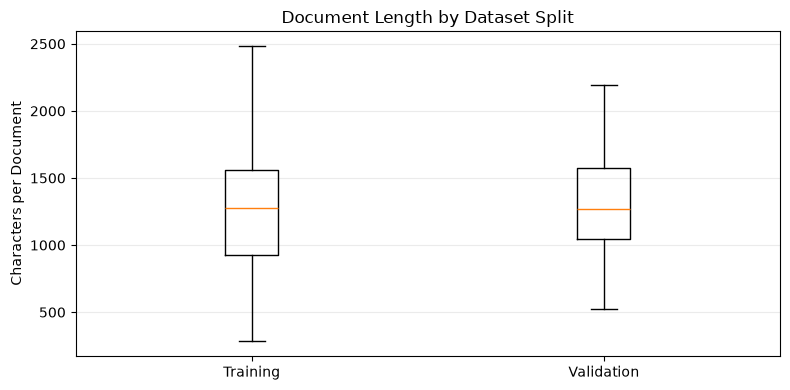

In [5]:
import matplotlib.pyplot as plt
from IPython.display import display

# Load only the training and validation splits for exploratory analysis.
# Keep the testing split untouched to avoid test-set-driven decisions.
split_files = {
    "Training": "NCBI_training.jsonl",
    "Validation": "NCBI_validation.jsonl",
}
records_by_split = {}

for split, file_name in split_files.items():
    file_path = processed_data_dir / file_name
    with file_path.open(encoding="utf-8") as source:
        records_by_split[split] = [json.loads(line) for line in source if line.strip()]

# Summarise dataset size and document character lengths.
scale_rows = []
for split, records in records_by_split.items():
    document_lengths = pd.Series([len(record["text"]) for record in records])
    entity_texts = [
        record["text"][entity["start"]:entity["end"]]
        for record in records
        for entity in record["entities"]
    ]
    unique_pmids = len({record["pmid"] for record in records})

    scale_rows.append({
        "Split": split,
        "Documents": len(records),
        "Unique PMIDs": unique_pmids,
        "Repeated Records": len(records) - unique_pmids,
        "Entity Mentions": len(entity_texts),
        "Unique Entity Texts": len(set(entity_texts)),
        "Mean Document Length": document_lengths.mean(),
        "Median Document Length": document_lengths.median(),
        "95th Percentile Length": document_lengths.quantile(0.95),
        "Maximum Document Length": document_lengths.max(),
    })

scale_summary = pd.DataFrame(scale_rows).set_index("Split")
display(scale_summary.round(2))

# Compare document-length distributions across splits.
plt.figure(figsize=(8, 4))
plt.boxplot(
    [[len(record["text"]) for record in records_by_split[split]] for split in split_files],
    tick_labels=list(split_files),
    showfliers=False,
)
plt.title("Document Length by Dataset Split")
plt.ylabel("Characters per Document")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### 3.2 实体分布

,Entities per Document,"Entities per 1,000 Characters",Zero-Entity Documents,Mean Entity Length,Median Entity Length,95th Percentile Entity Length,Maximum Entity Length,Single-Word Entities (%),Multi-Word Entities (%)
Split,,,,,,,,,
Training,8.68,6.86,0,15.19,14.0,37.0,80,46.69,53.31
Validation,7.87,5.93,0,15.74,15.0,37.0,74,42.69,57.31


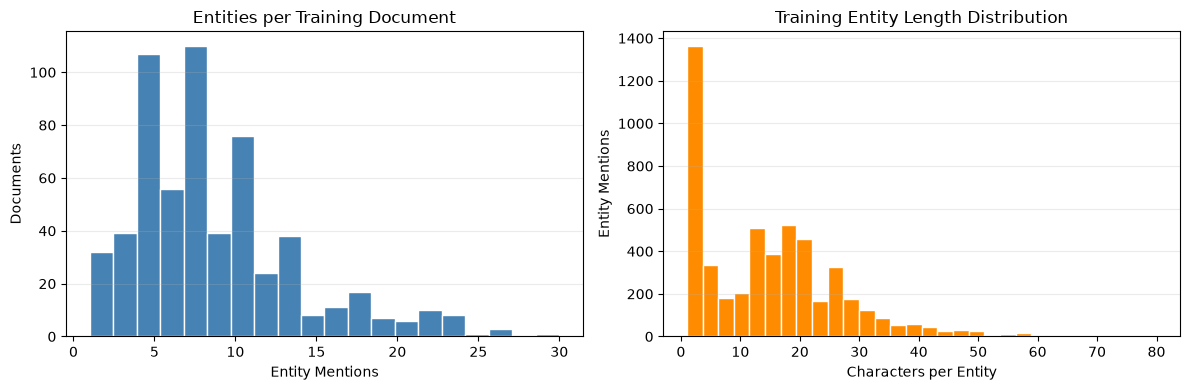

In [6]:
# Summarise entity density and character length for each split.
entity_rows = []
for split, records in records_by_split.items():
    entity_counts = pd.Series([len(record["entities"]) for record in records])
    entity_texts = [
        record["text"][entity["start"]:entity["end"]]
        for record in records
        for entity in record["entities"]
    ]
    entity_lengths = pd.Series([len(text) for text in entity_texts])
    total_characters = sum(len(record["text"]) for record in records)
    single_word_count = sum(len(text.split()) == 1 for text in entity_texts)

    entity_rows.append({
        "Split": split,
        "Entities per Document": entity_counts.mean(),
        "Entities per 1,000 Characters": len(entity_texts) / total_characters * 1000,
        "Zero-Entity Documents": int((entity_counts == 0).sum()),
        "Mean Entity Length": entity_lengths.mean(),
        "Median Entity Length": entity_lengths.median(),
        "95th Percentile Entity Length": entity_lengths.quantile(0.95),
        "Maximum Entity Length": entity_lengths.max(),
        "Single-Word Entities (%)": single_word_count / len(entity_texts) * 100,
        "Multi-Word Entities (%)": (len(entity_texts) - single_word_count) / len(entity_texts) * 100,
    })

entity_summary = pd.DataFrame(entity_rows).set_index("Split")
display(entity_summary.round(2))

# Plot the main entity distributions in the training set.
training_records = records_by_split["Training"]
training_entity_counts = [len(record["entities"]) for record in training_records]
training_entity_lengths = [
    entity["end"] - entity["start"]
    for record in training_records
    for entity in record["entities"]
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(training_entity_counts, bins=20, color="steelblue", edgecolor="white")
axes[0].set_title("Entities per Training Document")
axes[0].set_xlabel("Entity Mentions")
axes[0].set_ylabel("Documents")

axes[1].hist(training_entity_lengths, bins=30, color="darkorange", edgecolor="white")
axes[1].set_title("Training Entity Length Distribution")
axes[1].set_xlabel("Characters per Entity")
axes[1].set_ylabel("Entity Mentions")

for axis in axes:
    axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Number of entity types: 4
Entity types: CompositeMention, DiseaseClass, Modifier, SpecificDisease


Split,Training,Validation,Total,Total (%)
Entity Type,,,,
SpecificDisease,2972,412,3384,57.05
Modifier,1289,214,1503,25.34
DiseaseClass,769,126,895,15.09
CompositeMention,115,35,150,2.53


Split,Training (%),Validation (%)
Entity Type,,
CompositeMention,2.24,4.45
DiseaseClass,14.95,16.01
Modifier,25.05,27.19
SpecificDisease,57.76,52.35


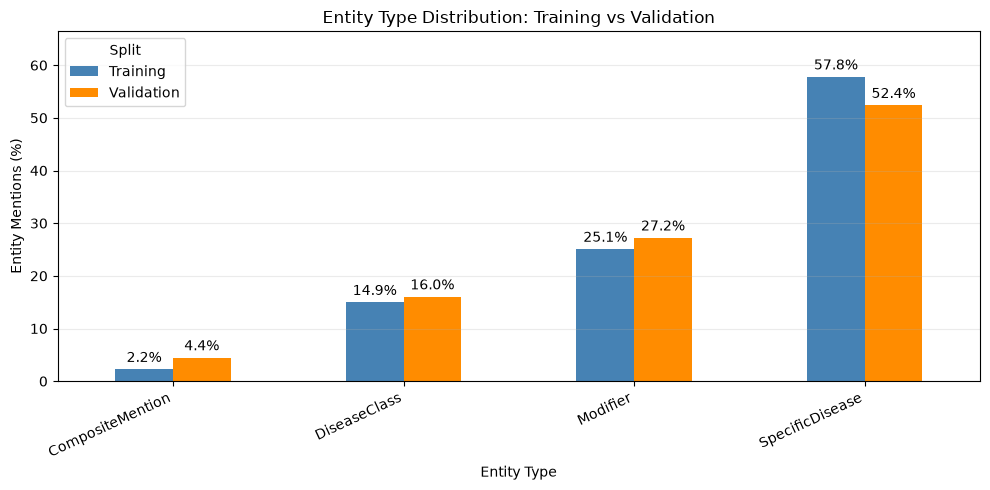

In [7]:
# Analyse entity mention types in the training and validation splits.
missing_type_records = [
    record["record_id"]
    for records in records_by_split.values()
    for record in records
    if any("type" not in entity for entity in record["entities"])
]
if missing_type_records:
    raise ValueError(
        "Entity type is missing from ProcessedData. "
        "Re-run Section 3.0 before this analysis."
    )

entity_types = sorted({
    entity["type"]
    for records in records_by_split.values()
    for record in records
    for entity in record["entities"]
})
print(f"Number of entity types: {len(entity_types)}")
print("Entity types:", ", ".join(entity_types))

type_distribution_rows = []
for split, records in records_by_split.items():
    split_types = [
        entity["type"]
        for record in records
        for entity in record["entities"]
    ]
    split_total = len(split_types)
    for entity_type in entity_types:
        count = split_types.count(entity_type)
        type_distribution_rows.append({
            "Split": split,
            "Entity Type": entity_type,
            "Count": count,
            "Percentage": count / split_total * 100,
        })

type_distribution = pd.DataFrame(type_distribution_rows)
type_count_summary = type_distribution.pivot(
    index="Entity Type", columns="Split", values="Count"
).reindex(columns=list(split_files)).astype(int)
type_count_summary["Total"] = type_count_summary.sum(axis=1)
type_count_summary["Total (%)"] = (
    type_count_summary["Total"]
    / type_count_summary["Total"].sum()
    * 100
)
display(type_count_summary.sort_values("Total", ascending=False).round(2))

type_percentage_summary = type_distribution.pivot(
    index="Entity Type", columns="Split", values="Percentage"
).reindex(columns=list(split_files))
display(type_percentage_summary.round(2).add_suffix(" (%)"))

# Compare within-split percentages so split size does not distort the chart.
plot_percentages = type_percentage_summary.loc[entity_types]
axis = plot_percentages.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "darkorange"],
)
for container in axis.containers:
    axis.bar_label(container, fmt="%.1f%%", padding=3)
plt.title("Entity Type Distribution: Training vs Validation")
plt.xlabel("Entity Type")
plt.ylabel("Entity Mentions (%)")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, plot_percentages.to_numpy().max() * 1.15)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


### 3.3 tokenized by two methods
#### 3.3.1 BioBERT

In [8]:
from transformers.models.bert.tokenization_bert import BertTokenizerFast

BIOBERT_MODEL = "dmis-lab/biobert-base-cased-v1.1"
# BioBERT v1.1 inherits the BERT-base-cased WordPiece vocabulary.

BIOBERT_TOKENIZER = "google-bert/bert-base-cased"

ENTITY_TYPES = (
    "SpecificDisease",
    "DiseaseClass",
    "CompositeMention",
    "Modifier",
)
BIO_LABELS = ["O"]
for entity_type in ENTITY_TYPES:
    BIO_LABELS.extend([
        f"B-{entity_type}",
        f"I-{entity_type}",
    ])
LABEL2ID = {
    label: label_id for label_id, label in enumerate(BIO_LABELS)
}
ID2LABEL = {
    label_id: label for label, label_id in LABEL2ID.items()
}

dataset_files = (
    "NCBI_training.jsonl",
    "NCBI_validation.jsonl",
    "NCBI_testing.jsonl",
)

biobert_output_dir = (
    project_dir / "Dataset" / "TokenizedData" / "BioBERT"
)
biobert_output_dir.mkdir(parents=True, exist_ok=True)

tokenized_training_path = (
    biobert_output_dir / "NCBI_training.jsonl"
)


def create_typed_bio_tags(offsets, entities, record_id):
    """Align character-level entities with BioBERT WordPieces."""
    bio_tags = ["O"] * len(offsets)

    for entity in sorted(
        entities, key=lambda item: (item["start"], item["end"])
    ):
        required_fields = {"start", "end", "type"}
        if not required_fields.issubset(entity):
            raise ValueError(
                f"Incomplete entity annotation in {record_id}: {entity}"
            )

        entity_start = entity["start"]
        entity_end = entity["end"]
        entity_type = entity["type"]
        if entity_type not in ENTITY_TYPES:
            raise ValueError(
                f"Unknown entity type {entity_type!r} in {record_id}"
            )

        token_indices = [
            token_index
            for token_index, (token_start, token_end) in enumerate(offsets)
            if token_start < entity_end and token_end > entity_start
        ]
        if not token_indices:
            raise ValueError(
                f"Entity [{entity_start}, {entity_end}) has no token "
                f"alignment in {record_id}"
            )

        first_token = token_indices[0]
        last_token = token_indices[-1]
        if (
            offsets[first_token][0] != entity_start
            or offsets[last_token][1] != entity_end
        ):
            raise ValueError(
                f"Entity boundary [{entity_start}, {entity_end}) is not "
                f"aligned with token boundaries in {record_id}"
            )

        if any(bio_tags[index] != "O" for index in token_indices):
            raise ValueError(
                f"Overlapping entities are not supported in {record_id}"
            )

        bio_tags[first_token] = f"B-{entity_type}"
        for token_index in token_indices[1:]:
            bio_tags[token_index] = f"I-{entity_type}"

    return bio_tags


def tokenize_dataset(
    input_path,
    output_path,
    tokenizer,
    model_name,
    tokenizer_name,
    include_gold_labels,
):
    document_count = 0
    token_count = 0

    with input_path.open(encoding="utf-8") as source:
        with output_path.open("w", encoding="utf-8") as destination:
            for line in source:
                if not line.strip():
                    continue

                record = json.loads(line)
                encoded = tokenizer(
                    record["text"],
                    add_special_tokens=False,
                    truncation=False,
                    return_attention_mask=True,
                    return_offsets_mapping=True,
                    verbose=False,
                )
                tokens = tokenizer.convert_ids_to_tokens(
                    encoded["input_ids"]
                )
                offsets = [
                    [start, end]
                    for start, end in encoded["offset_mapping"]
                ]

                has_invalid_offset = any(
                    not 0 <= token_start < token_end
                    <= len(record["text"])
                    for token_start, token_end in offsets
                )
                if has_invalid_offset:
                    raise ValueError(
                        f"Invalid token offset in {record['record_id']}"
                    )

                sequence_lengths = (
                    len(tokens),
                    len(encoded["input_ids"]),
                    len(encoded["attention_mask"]),
                    len(offsets),
                )
                bio_tags = None
                if include_gold_labels:
                    bio_tags = create_typed_bio_tags(
                        offsets,
                        record["entities"],
                        record["record_id"],
                    )
                    sequence_lengths += (len(bio_tags),)
                if len(set(sequence_lengths)) != 1:
                    raise ValueError(
                        f"Token alignment failed for {record['record_id']}"
                    )

                tokenized_record = {
                    "record_id": record["record_id"],
                    "pmid": record["pmid"],
                    "model": model_name,
                    "tokenizer": tokenizer_name,
                    "text": record["text"],
                    "entities": [],
                    "tokens": tokens,
                    "input_ids": encoded["input_ids"],
                    "attention_mask": encoded["attention_mask"],
                    "offset_mapping": offsets,
                    "bio_tags": [],
                }
                if include_gold_labels:
                    tokenized_record["entities"] = record["entities"]
                    tokenized_record["bio_tags"] = bio_tags
                destination.write(
                    json.dumps(tokenized_record, ensure_ascii=False)
                    + "\n"
                )
                document_count += 1
                token_count += len(tokens)

    return document_count, token_count


# A fast tokenizer is required to return character offsets.
biobert_tokenizer = BertTokenizerFast.from_pretrained(
    BIOBERT_TOKENIZER
)
if not biobert_tokenizer.is_fast:
    raise RuntimeError(
        "BioBERT fast tokenizer is required for offset mapping."
    )

for file_name in dataset_files:
    input_path = processed_data_dir / file_name
    output_path = biobert_output_dir / file_name
    include_gold_labels = file_name == "NCBI_training.jsonl"
    document_count, token_count = tokenize_dataset(
        input_path,
        output_path,
        biobert_tokenizer,
        BIOBERT_MODEL,
        BIOBERT_TOKENIZER,
        include_gold_labels,
    )
    print(
        f"Saved {document_count} BioBERT-tokenized documents to: "
        f"{output_path}"
    )
    print(f"Total WordPiece tokens: {token_count}")
    print(
        "Gold entities and BIO tags: "
        + ("included" if include_gold_labels else "masked")
    )

Saved 593 BioBERT-tokenized documents to: /home/administrator/MedNLP_Research/Dataset/TokenizedData/BioBERT/NCBI_training.jsonl
Total WordPiece tokens: 184552
Gold entities and BIO tags: included
Saved 100 BioBERT-tokenized documents to: /home/administrator/MedNLP_Research/Dataset/TokenizedData/BioBERT/NCBI_validation.jsonl
Total WordPiece tokens: 32132
Gold entities and BIO tags: masked
Saved 100 BioBERT-tokenized documents to: /home/administrator/MedNLP_Research/Dataset/TokenizedData/BioBERT/NCBI_testing.jsonl
Total WordPiece tokens: 33092
Gold entities and BIO tags: masked


#### 3.3.2 BioBERT 分词结果分析

,Documents,Total WordPieces,Mean WordPieces,Median WordPieces,95th Percentile,Maximum WordPieces,Documents > 510
Split,,,,,,,
Training,593,184552,311.22,307.0,492.8,762,24
Validation,100,32132,321.32,312.0,485.3,529,4
Testing,100,33092,330.92,316.5,496.1,684,3


,Count,Mean,Median,Minimum,95th Percentile,Maximum
Measurement,,,,,,
WordPieces per document,593,311.22,307.0,74,492.8,762
Characters per WordPiece,184552,3.45,3.0,1,9.0,16
WordPieces per entity,5145,4.76,4.0,1,11.0,33


,Content WordPiece Limit,Documents Exceeding Limit,Documents Exceeding Limit (%)
Model Max Length,,,
128,126,577,97.30
256,254,396,66.78
512,510,24,4.05


,Count,Percentage
Metric,,
Single-WordPiece entities,243,4.72
Multi-WordPiece entities,4902,95.28
Boundary-aligned entities,5145,100.00
Boundary-unaligned entities,0,0.00


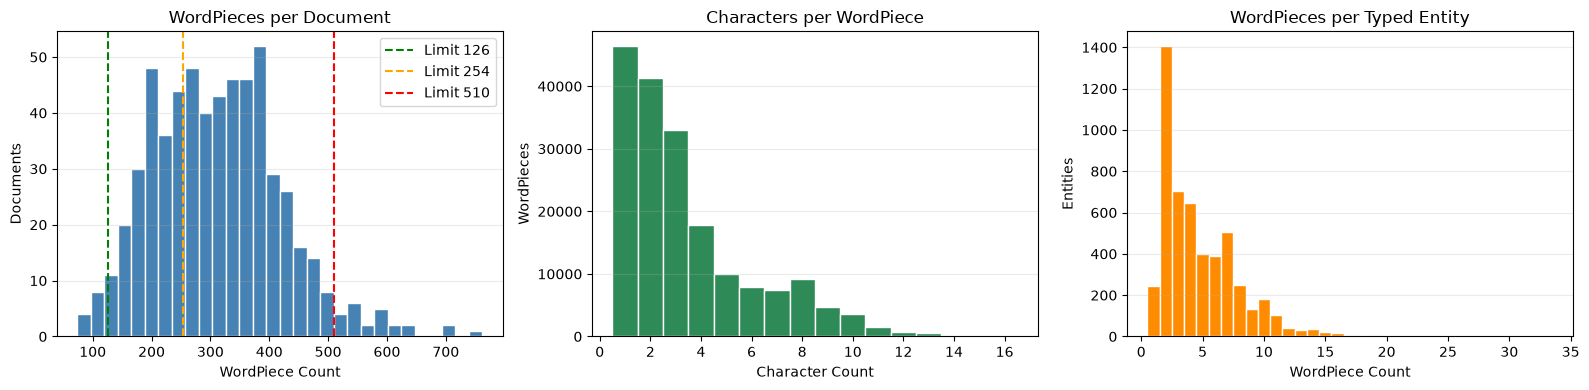

,Count,Percentage
Label,,
O,160047,86.722
B-SpecificDisease,2972,1.610
I-SpecificDisease,12461,6.752
B-DiseaseClass,769,0.417
I-DiseaseClass,2919,1.582
B-CompositeMention,115,0.062
I-CompositeMention,946,0.513
B-Modifier,1289,0.698
I-Modifier,3034,1.644


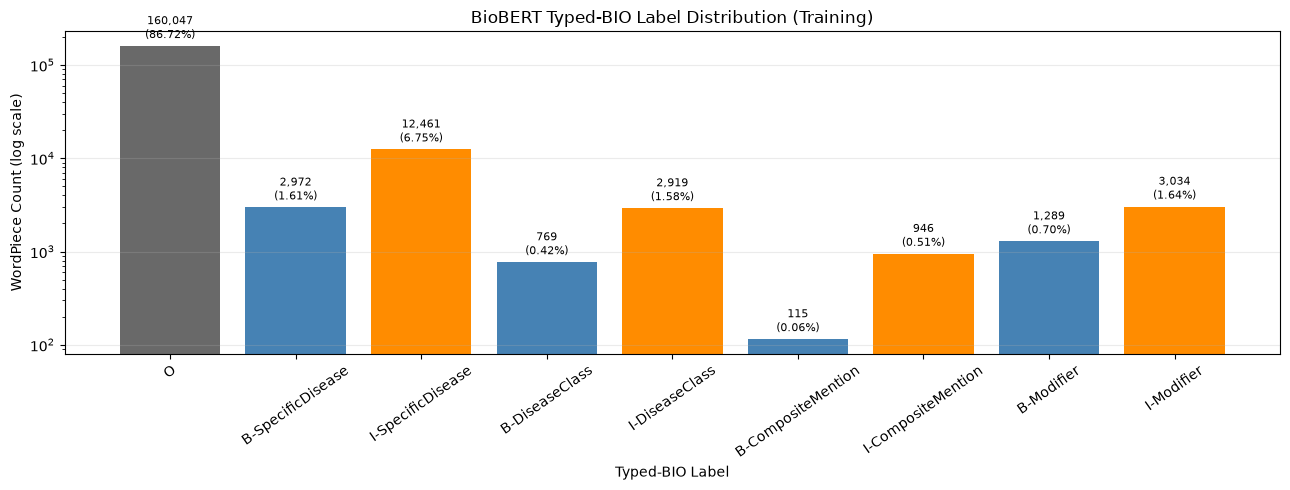

In [9]:
from collections import Counter

# Load all BioBERT-tokenized splits and validate the shared JSONL schema.
biobert_files = {
    "Training": "NCBI_training.jsonl",
    "Validation": "NCBI_validation.jsonl",
    "Testing": "NCBI_testing.jsonl",
}
biobert_records_by_split = {}
required_tokenized_fields = {
    "record_id",
    "pmid",
    "model",
    "tokenizer",
    "text",
    "entities",
    "tokens",
    "input_ids",
    "attention_mask",
    "offset_mapping",
    "bio_tags",
}

for split, file_name in biobert_files.items():
    file_path = biobert_output_dir / file_name
    with file_path.open(encoding="utf-8") as source:
        records = [
            json.loads(line) for line in source if line.strip()
        ]

    for record in records:
        missing_fields = required_tokenized_fields - set(record)
        if missing_fields:
            raise ValueError(
                f"Missing fields {sorted(missing_fields)} in "
                f"{record.get('record_id', file_name)}"
            )
        sequence_lengths = {
            len(record["tokens"]),
            len(record["input_ids"]),
            len(record["attention_mask"]),
            len(record["offset_mapping"]),
        }
        if len(sequence_lengths) != 1:
            raise ValueError(
                f"Token sequence mismatch in {record['record_id']}"
            )

        if split == "Training":
            if len(record["bio_tags"]) != len(record["tokens"]):
                raise ValueError(
                    f"BIO alignment mismatch in {record['record_id']}"
                )
        elif record["entities"] or record["bio_tags"]:
            raise ValueError(
                f"Gold labels are not masked in {record['record_id']}"
            )

    biobert_records_by_split[split] = records

# Preserve the original analysis scope: descriptive statistics use Training.
biobert_records = biobert_records_by_split["Training"]

# Summarise tokenization volume for every split without using masked gold.
split_token_rows = []
for split, records in biobert_records_by_split.items():
    split_token_counts = pd.Series([
        len(record["tokens"]) for record in records
    ])
    split_token_rows.append({
        "Split": split,
        "Documents": len(records),
        "Total WordPieces": int(split_token_counts.sum()),
        "Mean WordPieces": split_token_counts.mean(),
        "Median WordPieces": split_token_counts.median(),
        "95th Percentile": split_token_counts.quantile(0.95),
        "Maximum WordPieces": int(split_token_counts.max()),
        "Documents > 510": int((split_token_counts > 510).sum()),
    })
split_token_summary = pd.DataFrame(split_token_rows).set_index("Split")
display(split_token_summary.round(2))

document_token_counts = [
    len(record["tokens"]) for record in biobert_records
]
token_character_lengths = [
    token_end - token_start
    for record in biobert_records
    for token_start, token_end in record["offset_mapping"]
]

entity_wordpiece_counts = []
boundary_aligned_entities = 0

for record in biobert_records:
    offsets = record["offset_mapping"]
    token_starts = {token_start for token_start, _ in offsets}
    token_ends = {token_end for _, token_end in offsets}

    for entity in record["entities"]:
        wordpiece_count = sum(
            token_start < entity["end"]
            and token_end > entity["start"]
            for token_start, token_end in offsets
        )
        entity_wordpiece_counts.append(wordpiece_count)

        is_boundary_aligned = (
            entity["start"] in token_starts
            and entity["end"] in token_ends
        )
        boundary_aligned_entities += int(is_boundary_aligned)


def describe_values(name, values):
    values = pd.Series(values)
    return {
        "Measurement": name,
        "Count": len(values),
        "Mean": values.mean(),
        "Median": values.median(),
        "Minimum": values.min(),
        "95th Percentile": values.quantile(0.95),
        "Maximum": values.max(),
    }


token_statistics = pd.DataFrame([
    describe_values("WordPieces per document", document_token_counts),
    describe_values("Characters per WordPiece", token_character_lengths),
    describe_values("WordPieces per entity", entity_wordpiece_counts),
]).set_index("Measurement")
display(token_statistics.round(2))

# Reserve two positions for [CLS] and [SEP].
capacity_rows = []
for model_max_length in (128, 256, 512):
    content_limit = model_max_length - 2
    exceeding_count = sum(
        count > content_limit for count in document_token_counts
    )
    capacity_rows.append({
        "Model Max Length": model_max_length,
        "Content WordPiece Limit": content_limit,
        "Documents Exceeding Limit": exceeding_count,
        "Documents Exceeding Limit (%)": (
            exceeding_count / len(document_token_counts) * 100
        ),
    })

capacity_summary = pd.DataFrame(capacity_rows).set_index(
    "Model Max Length"
)
display(capacity_summary.round(2))

total_entities = len(entity_wordpiece_counts)
single_wordpiece_entities = sum(
    count == 1 for count in entity_wordpiece_counts
)
entity_alignment_summary = pd.DataFrame({
    "Metric": [
        "Single-WordPiece entities",
        "Multi-WordPiece entities",
        "Boundary-aligned entities",
        "Boundary-unaligned entities",
    ],
    "Count": [
        single_wordpiece_entities,
        total_entities - single_wordpiece_entities,
        boundary_aligned_entities,
        total_entities - boundary_aligned_entities,
    ],
}).set_index("Metric")
entity_alignment_summary["Percentage"] = (
    entity_alignment_summary["Count"] / total_entities * 100
)
display(entity_alignment_summary.round(2))

# Plot document, token, and entity tokenization distributions.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(
    document_token_counts,
    bins=30,
    color="steelblue",
    edgecolor="white",
)
for limit, color in zip((126, 254, 510), ("green", "orange", "red")):
    axes[0].axvline(
        limit,
        color=color,
        linestyle="--",
        label=f"Limit {limit}",
    )
axes[0].set_title("WordPieces per Document")
axes[0].set_xlabel("WordPiece Count")
axes[0].set_ylabel("Documents")
axes[0].legend()

token_length_bins = np.arange(
    0.5, max(token_character_lengths) + 1.5, 1
)
axes[1].hist(
    token_character_lengths,
    bins=token_length_bins,
    color="seagreen",
    edgecolor="white",
)
axes[1].set_title("Characters per WordPiece")
axes[1].set_xlabel("Character Count")
axes[1].set_ylabel("WordPieces")

entity_piece_bins = np.arange(
    0.5, max(entity_wordpiece_counts) + 1.5, 1
)
axes[2].hist(
    entity_wordpiece_counts,
    bins=entity_piece_bins,
    color="darkorange",
    edgecolor="white",
)
axes[2].set_title("WordPieces per Typed Entity")
axes[2].set_xlabel("WordPiece Count")
axes[2].set_ylabel("Entities")

for axis in axes:
    axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# Analyse the 4 * 2 + 1 typed-BIO labels in the training split only.
training_label_counts = Counter(
    tag
    for record in biobert_records
    for tag in record["bio_tags"]
)
unknown_labels = set(training_label_counts) - set(BIO_LABELS)
if unknown_labels:
    raise ValueError(
        f"Unknown BIO labels found: {sorted(unknown_labels)}"
    )

label_distribution = pd.DataFrame({
    "Label": BIO_LABELS,
    "Count": [training_label_counts[label] for label in BIO_LABELS],
})
label_distribution["Percentage"] = (
    label_distribution["Count"]
    / label_distribution["Count"].sum()
    * 100
)
display(label_distribution.set_index("Label").round(3))

label_colors = [
    "dimgray"
    if label == "O"
    else "steelblue"
    if label.startswith("B-")
    else "darkorange"
    for label in label_distribution["Label"]
]
fig, axis = plt.subplots(figsize=(13, 5))
bars = axis.bar(
    label_distribution["Label"],
    label_distribution["Count"],
    color=label_colors,
)
axis.set_yscale("log")
axis.bar_label(
    bars,
    labels=[
        f"{count:,}\n({percentage:.2f}%)"
        for count, percentage in zip(
            label_distribution["Count"],
            label_distribution["Percentage"],
        )
    ],
    padding=3,
    fontsize=8,
)
axis.set_title("BioBERT Typed-BIO Label Distribution (Training)")
axis.set_xlabel("Typed-BIO Label")
axis.set_ylabel("WordPiece Count (log scale)")
axis.tick_params(axis="x", rotation=35)
axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## **_4. Standardized Testing_**

In [10]:
from collections import Counter
import json
from pathlib import Path

import pandas as pd

EVALUATION_ENTITY_TYPES = (
    "SpecificDisease",
    "DiseaseClass",
    "CompositeMention",
    "Modifier",
)


def load_jsonl_records(file_path):
    records = []
    with Path(file_path).open(encoding="utf-8") as source:
        for line_number, line in enumerate(source, start=1):
            if not line.strip():
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as error:
                raise ValueError(
                    f"Invalid JSON on line {line_number}: {file_path}"
                ) from error
    return records


def index_records(records, source_name):
    indexed = {}
    for record in records:
        record_id = record.get("record_id")
        if not isinstance(record_id, str) or not record_id:
            raise ValueError(f"Missing record_id in {source_name}")
        if record_id in indexed:
            raise ValueError(
                f"Duplicate record_id {record_id} in {source_name}"
            )
        indexed[record_id] = record
    return indexed


def validate_entity(entity, record_id, text_length):
    if not isinstance(entity, dict):
        raise TypeError(f"Entity in {record_id} must be a dictionary")
    if set(entity) != {"start", "end", "type"}:
        raise ValueError(
            f"Entity in {record_id} must contain only start, end, and type"
        )

    start, end = entity["start"], entity["end"]
    entity_type = entity["type"]
    valid_offsets = (
        isinstance(start, int)
        and not isinstance(start, bool)
        and isinstance(end, int)
        and not isinstance(end, bool)
    )
    if not valid_offsets or not 0 <= start < end <= text_length:
        raise ValueError(
            f"Invalid span [{start}, {end}) in {record_id}"
        )
    if entity_type not in EVALUATION_ENTITY_TYPES:
        raise ValueError(
            f"Invalid entity type {entity_type!r} in {record_id}"
        )
    return start, end, entity_type


def validate_prediction(prediction, gold_record):
    required_fields = {"record_id", "pmid", "entities"}
    if set(prediction) != required_fields:
        raise ValueError(
            f"Prediction {prediction.get('record_id')} must contain only "
            "record_id, pmid, and entities"
        )
    record_id = prediction["record_id"]
    if prediction["pmid"] != gold_record["pmid"]:
        raise ValueError(f"PMID mismatch for {record_id}")
    if not isinstance(prediction["entities"], list):
        raise ValueError(f"entities must be a list in {record_id}")

    text_length = len(gold_record["text"])
    entities = [
        validate_entity(entity, record_id, text_length)
        for entity in prediction["entities"]
    ]
    if entities != sorted(entities):
        raise ValueError(f"Entities are not sorted in {record_id}")
    if len(entities) != len(set(entities)):
        raise ValueError(f"Duplicate entities in {record_id}")

    spans = [(start, end) for start, end, _ in entities]
    if len(spans) != len(set(spans)):
        raise ValueError(
            f"A span has multiple predicted types in {record_id}"
        )
    return entities


def calculate_prf(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall
        else 0.0
    )
    return {
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }


def set_counts(gold_values, predicted_values):
    return (
        len(gold_values & predicted_values),
        len(predicted_values - gold_values),
        len(gold_values - predicted_values),
    )


def boundary_counts(gold_values, predicted_values):
    gold_counter = Counter(gold_values)
    predicted_counter = Counter(predicted_values)
    return (
        sum((gold_counter & predicted_counter).values()),
        sum((predicted_counter - gold_counter).values()),
        sum((gold_counter - predicted_counter).values()),
    )


def spans_to_characters(spans):
    characters = set()
    for start, end in spans:
        characters.update(range(start, end))
    return characters


def add_counts(total, current):
    for index, value in enumerate(current):
        total[index] += value


def evaluate_standardized_records(gold_records, prediction_records):
    gold_by_id = index_records(gold_records, "gold records")
    pred_by_id = index_records(prediction_records, "predictions")
    missing = sorted(set(gold_by_id) - set(pred_by_id))
    extra = sorted(set(pred_by_id) - set(gold_by_id))
    if missing or extra:
        raise ValueError(
            f"Record mismatch: missing={missing}, extra={extra}"
        )

    typed_total = [0, 0, 0]
    span_only_total = [0, 0, 0]
    start_total = [0, 0, 0]
    end_total = [0, 0, 0]
    character_total = [0, 0, 0]
    per_type_totals = {
        entity_type: [0, 0, 0]
        for entity_type in EVALUATION_ENTITY_TYPES
    }
    type_confusion = {
        gold_type: {pred_type: 0 for pred_type in EVALUATION_ENTITY_TYPES}
        for gold_type in EVALUATION_ENTITY_TYPES
    }
    matched_span_count = 0
    correct_type_count = 0
    gold_entity_count = 0
    predicted_entity_count = 0

    for record_id, gold_record in gold_by_id.items():
        text_length = len(gold_record["text"])
        gold_entities = [
            validate_entity(entity, record_id, text_length)
            for entity in gold_record["entities"]
        ]
        predicted_entities = validate_prediction(
            pred_by_id[record_id], gold_record
        )

        gold_spans = [(start, end) for start, end, _ in gold_entities]
        predicted_spans = [
            (start, end) for start, end, _ in predicted_entities
        ]
        if len(gold_spans) != len(set(gold_spans)):
            raise ValueError(
                f"A gold span has multiple types in {record_id}"
            )

        gold_entity_count += len(gold_entities)
        predicted_entity_count += len(predicted_entities)
        gold_entity_set = set(gold_entities)
        predicted_entity_set = set(predicted_entities)
        gold_span_set = set(gold_spans)
        predicted_span_set = set(predicted_spans)

        add_counts(
            typed_total,
            set_counts(gold_entity_set, predicted_entity_set),
        )
        add_counts(
            span_only_total,
            set_counts(gold_span_set, predicted_span_set),
        )

        for entity_type in EVALUATION_ENTITY_TYPES:
            gold_for_type = {
                entity for entity in gold_entity_set
                if entity[2] == entity_type
            }
            predicted_for_type = {
                entity for entity in predicted_entity_set
                if entity[2] == entity_type
            }
            add_counts(
                per_type_totals[entity_type],
                set_counts(gold_for_type, predicted_for_type),
            )

        gold_type_by_span = {
            (start, end): entity_type
            for start, end, entity_type in gold_entities
        }
        predicted_type_by_span = {
            (start, end): entity_type
            for start, end, entity_type in predicted_entities
        }
        for span in gold_span_set & predicted_span_set:
            gold_type = gold_type_by_span[span]
            predicted_type = predicted_type_by_span[span]
            type_confusion[gold_type][predicted_type] += 1
            matched_span_count += 1
            correct_type_count += int(gold_type == predicted_type)

        add_counts(
            start_total,
            boundary_counts(
                [start for start, _ in gold_spans],
                [start for start, _ in predicted_spans],
            ),
        )
        add_counts(
            end_total,
            boundary_counts(
                [end for _, end in gold_spans],
                [end for _, end in predicted_spans],
            ),
        )
        add_counts(
            character_total,
            set_counts(
                spans_to_characters(gold_spans),
                spans_to_characters(predicted_spans),
            ),
        )

    per_type = {}
    for entity_type, counts in per_type_totals.items():
        values = calculate_prf(*counts)
        values["support"] = counts[0] + counts[2]
        values["predicted_count"] = counts[0] + counts[1]
        per_type[entity_type] = values

    typed_macro = {
        metric: sum(values[metric] for values in per_type.values())
        / len(EVALUATION_ENTITY_TYPES)
        for metric in ("precision", "recall", "f1")
    }
    wrong_type_count = matched_span_count - correct_type_count

    return {
        "averaging": "micro",
        "document_count": len(gold_by_id),
        "gold_entity_count": gold_entity_count,
        "predicted_entity_count": predicted_entity_count,
        "typed_exact": calculate_prf(*typed_total),
        "typed_macro": typed_macro,
        "per_type": per_type,
        "span_only_exact": calculate_prf(*span_only_total),
        "exact_span_type": {
            "matched_span_count": matched_span_count,
            "correct_type_count": correct_type_count,
            "wrong_type_count": wrong_type_count,
            "accuracy": (
                correct_type_count / matched_span_count
                if matched_span_count
                else 0.0
            ),
        },
        "type_confusion_matrix": type_confusion,
        "start_boundary": calculate_prf(*start_total),
        "end_boundary": calculate_prf(*end_total),
        "character_overlap": calculate_prf(*character_total),
    }


def evaluate_model_predictions(prediction_records, split):
    # Select the gold file while keeping one shared public evaluation entry point.
    if not isinstance(prediction_records, list):
        raise TypeError("prediction_records must be a list of dictionaries")
    if not all(isinstance(record, dict) for record in prediction_records):
        raise TypeError("Every prediction record must be a dictionary")

    if not isinstance(split, str):
        raise TypeError("split must be a string: 'validation' or 'test'")

    split_name = split.strip().lower()
    gold_file_names = {
        "validation": "NCBI_validation.jsonl",
        "test": "NCBI_testing.jsonl",
    }
    if split_name not in gold_file_names:
        raise ValueError("split must be 'validation' or 'test'")

    current_directory = Path.cwd().resolve()
    project_root = next(
        (
            path
            for path in (current_directory, *current_directory.parents)
            if (path / "Dataset" / "ProcessedData").is_dir()
        ),
        None,
    )
    if project_root is None:
        raise FileNotFoundError(
            "Could not locate Dataset/ProcessedData from the current directory"
        )

    gold_path = (
        project_root
        / "Dataset"
        / "ProcessedData"
        / gold_file_names[split_name]
    )
    return evaluate_standardized_records(
        load_jsonl_records(gold_path),
        prediction_records,
    )


def metrics_to_table(metrics):
    rows = []

    def append_prf_row(metric_name, values):
        rows.append({
            "Metric": metric_name,
            "TP": values.get("true_positives"),
            "FP": values.get("false_positives"),
            "FN": values.get("false_negatives"),
            "Precision": values["precision"],
            "Recall": values["recall"],
            "F1": values["f1"],
        })

    append_prf_row("Typed exact (micro)", metrics["typed_exact"])
    append_prf_row("Typed macro", metrics["typed_macro"])
    for entity_type in EVALUATION_ENTITY_TYPES:
        append_prf_row(
            f"Typed: {entity_type}",
            metrics["per_type"][entity_type],
        )
    append_prf_row("Span-only exact", metrics["span_only_exact"])
    append_prf_row("Start boundary", metrics["start_boundary"])
    append_prf_row("End boundary", metrics["end_boundary"])
    append_prf_row("Character overlap", metrics["character_overlap"])
    return pd.DataFrame(rows).set_index("Metric")


def type_confusion_to_table(metrics):
    table = pd.DataFrame.from_dict(
        metrics["type_confusion_matrix"], orient="index"
    )
    return table.reindex(
        index=EVALUATION_ENTITY_TYPES,
        columns=EVALUATION_ENTITY_TYPES,
        fill_value=0,
    ).rename_axis("Gold type").rename_axis("Predicted type", axis=1)


def save_metrics(metrics, output_path):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with output_path.open("w", encoding="utf-8") as destination:
        json.dump(metrics, destination, indent=2, ensure_ascii=False)


# Example usage after the model has produced prediction_records in memory:
# metrics = evaluate_model_predictions(prediction_records, "test")
# display(metrics_to_table(metrics).round(4))
# display(type_confusion_to_table(metrics))
# save_metrics(
#     metrics,
#     project_dir / "results" / "B1_test_metrics.json",
# )


print("Standardized evaluation functions are ready.")

Standardized evaluation functions are ready.


## 5. Fine-tuning

All training and evaluation code is defined inline below. Training uses 512-token windows
with 64-token overlap, supervises each training token once, and averages overlapping logits
before document-level decoding. Checkpoints are selected by Validation typed exact-span
micro F1. Test data is loaded for evaluation only after each experiment locks its settings
and selects all three seed checkpoints.

Each stage has one progress bar with the current trial, epoch, loss and Validation F1.
Fixed E1 settings are batch size 8, weight decay 0.01, constant scheduler, patience 3,
CrossEntropy and search seed 9444. The epoch budget is 30.


In [11]:
# Load the inline training dependencies
from contextlib import nullcontext
from dataclasses import asdict, dataclass, field, replace
from datetime import datetime
from zoneinfo import ZoneInfo
import math
import time
import statistics
import json
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm import tqdm
from transformers import AutoTokenizer

# Keep the full formal protocol enabled by default
SMOKE_TEST = False
CUDA_FAST_MODE = True
RUN_E1_STAGE4 = True
FINAL_SEEDS = (42, 9444, 2026)

LABELS = ['O'] + [f'{prefix}-{kind}' for kind in EVALUATION_ENTITY_TYPES for prefix in ('B', 'I')]


# Select device
def choose_training_device(torch):
    if getattr(torch.backends, 'mps', None) and torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# Make windows
def make_windows(records, tokenizer, max_length, stride):
    """Keep full-document token indices; supervise overlap tokens only once."""
    capacity = max_length - 2
    if not 0 <= stride < capacity:
        raise ValueError('stride must be between 0 and max_length - 3')
    windows = []
    for doc, record in enumerate(records):
        ids, tags = record['input_ids'], record['bio_tags']
        if not len(ids) == len(tags) == len(record['offset_mapping']):
            raise ValueError(f"Unaligned tokens: {record['record_id']}")
        covered = 0
        for start in range(0, len(ids), capacity - stride):
            end = min(start + capacity, len(ids))
            labels = [LABELS.index(tag) if i >= covered else -100
                      for i, tag in enumerate(tags[start:end], start)]
            windows.append({'doc': doc, 'start': start, 'end': end,
                            'input_ids': [tokenizer.cls_token_id] + ids[start:end] + [tokenizer.sep_token_id],
                            'labels': [-100] + labels + [-100]})
            covered = end
            if end == len(ids):
                break
    return windows


# Decode document
def decode_document(record, tag_ids):
    """Repair illegal I transitions as B; report their original count."""
    entities, active, illegal = [], None, 0
    for (start, end), label in zip(record['offset_mapping'], tag_ids):
        tag = LABELS[int(label)]
        prefix, kind = ('O', None) if tag == 'O' else tag.split('-', 1)
        if prefix == 'I' and (active is None or active['type'] != kind):
            illegal += 1
            prefix = 'B'
        if prefix != 'I' and active is not None:
            entities.append(active)
            active = None
        if prefix == 'B':
            active = {'start': start, 'end': end, 'type': kind}
        elif prefix == 'I':
            active['end'] = end
    if active is not None:
        entities.append(active)
    return {'record_id': record['record_id'], 'pmid': record['pmid'], 'entities': entities}, illegal


# Save json
def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str) + '\n', encoding='utf-8')


# Synchronize device
def synchronize_device(torch, device):
    if device.type == 'cuda':
        torch.cuda.synchronize()
    elif device.type == 'mps':
        torch.mps.synchronize()


# Training class weights
def training_class_weights(windows, torch):
    counts = torch.zeros(len(LABELS), dtype=torch.float64)
    for window in windows:
        labels = [label for label in window['labels'] if label != -100]
        counts += torch.bincount(torch.tensor(labels, dtype=torch.long), minlength=len(LABELS))
    present = counts > 0
    weights = torch.zeros_like(counts)
    weights[present] = counts.sum() / (present.sum() * counts[present])
    return weights.float()


# Learning rate factor
def learning_rate_factor(step, total_steps, scheduler):
    if scheduler == 'constant':
        return 1.0
    if scheduler not in {'linear', 'linear_warmup'}:
        raise ValueError(f'Unknown scheduler {scheduler}')
    warmup = math.ceil(total_steps * 0.1) if scheduler == 'linear_warmup' else 0
    if step < warmup:
        return step / max(1, warmup)
    return max(0.0, (total_steps - step) / max(1, total_steps - warmup))


# Configure runtime
def configure_runtime(config, device):
    import torch

    fast = config.cuda_fast_mode and device.type == 'cuda'
    torch.use_deterministic_algorithms(not fast, warn_only=True)
    if device.type == 'cuda':
        torch.backends.cudnn.benchmark = fast
        torch.backends.cudnn.deterministic = not fast
        torch.set_float32_matmul_precision('high' if fast else 'highest')
    return torch.bfloat16 if fast and torch.cuda.is_bf16_supported() else None


# Precision context
def precision_context(device, amp_dtype):
    import torch

    return torch.autocast(device_type=device.type, dtype=amp_dtype) if amp_dtype is not None else nullcontext()


# Make collator
def make_collator(tokenizer, device, align=False):
    import torch

    def collate(windows):
        length = max(len(window['input_ids']) for window in windows)
        if align:
            length = math.ceil(length / 8) * 8
        inputs = torch.tensor([w['input_ids'] + [tokenizer.pad_token_id] * (length - len(w['input_ids'])) for w in windows], device=device)
        mask = torch.tensor([[1] * len(w['input_ids']) + [0] * (length - len(w['input_ids'])) for w in windows], device=device)
        labels = torch.tensor([w['labels'] + [-100] * (length - len(w['labels'])) for w in windows], device=device)
        return windows, {'input_ids': inputs, 'attention_mask': mask, 'labels': labels}

    return collate


# Release device memory
def release_device_memory(torch, device):
    import gc

    gc.collect()
    if device.type == 'mps':
        torch.mps.synchronize()
        torch.mps.empty_cache()
    elif device.type == 'cuda':
        torch.cuda.empty_cache()


# Load e1 split
def load_e1_split(config, tokenizer, name):
    records = load_jsonl_records(config.root / f'Dataset/TokenizedData/BioBERT/NCBI_{name}.jsonl')
    if config.limit_docs is not None:
        records = records[:config.limit_docs]
    gold = None
    if name != 'training':
        gold = index_records(load_jsonl_records(config.root / f'Dataset/ProcessedData/NCBI_{name}.jsonl'), name)
    for record in records:
        if record.get('model') != config.model:
            raise ValueError('Tokenized data model differs from the configured model')
        encoded = tokenizer(record['text'], add_special_tokens=False,
                            return_offsets_mapping=True, verbose=False)
        if encoded['input_ids'] != record['input_ids'] or [list(x) for x in encoded['offset_mapping']] != record['offset_mapping']:
            raise ValueError(f"Tokenizer mismatch for {record['record_id']}")
        if gold is not None:
            reference = gold[record['record_id']]
            if reference['pmid'] != record['pmid'] or reference['text'] != record['text']:
                raise ValueError('Gold and tokenized documents differ')
            record['entities'] = reference['entities']
            record['bio_tags'] = ['O'] * len(record['input_ids'])
    if not records:
        raise ValueError(f'Empty {name} split')
    return records, make_windows(records, tokenizer, config.max_length, config.stride)


# Best trial
def best_trial(trials):
    return max(trials, key=lambda trial: trial['validation_f1'])


# Summarize seeds
def summarize_seeds(trials, tests):
    import statistics

    def describe(values):
        return {'mean': statistics.mean(values), 'std': statistics.stdev(values)}

    summary = {'seeds': [trial['config']['seed'] for trial in trials],
               'standard_deviation': 'sample ddof 1', 'validation': {}, 'test': {}}
    for metric in ('precision', 'recall', 'f1'):
        summary['validation'][metric] = describe([trial['validation']['typed_exact'][metric] for trial in trials])
        if tests:
            summary['test'][metric] = describe([test['metrics']['typed_exact'][metric] for test in tests])
    summary['validation']['macro_f1'] = describe([trial['validation']['typed_macro']['f1'] for trial in trials])
    if tests:
        summary['test']['macro_f1'] = describe([test['metrics']['typed_macro']['f1'] for test in tests])
    summary['training_seconds'] = describe([trial['training_seconds'] for trial in trials])
    return summary


# Configure output
def configure_output():
    from huggingface_hub.utils import disable_progress_bars
    from huggingface_hub.utils import logging as hub_logging
    from transformers.utils import logging as transformers_logging

    hub_logging.set_verbosity_error()
    disable_progress_bars()
    transformers_logging.set_verbosity_error()
    transformers_logging.disable_progress_bar()

configure_output()


In [12]:
# Refresh one stage progress bar instead of printing epoch logs
_ACTIVE_PROGRESS = None


def report_epoch(epoch, budget, loss, f1, best):
    if _ACTIVE_PROGRESS is not None:
        _ACTIVE_PROGRESS.set_postfix({
            'epoch': f'{epoch}/{budget}', 'loss': f'{loss:.4f}',
            'Val F1': f'{f1:.2%}', 'best': f'{best:.2%}',
        }, refresh=True)


# Start each experiment with fresh paths and shared training data
def prepare_experiment(name, config, runner, evaluator):
    output_dir = config.root / config.output_dir
    output_dir.mkdir(parents=True, exist_ok=False)
    (output_dir / '.gitignore').write_text('*\n', encoding='utf-8')
    with tqdm(total=3, desc=f'{name} setup', leave=False) as progress:
        tokenizer = AutoTokenizer.from_pretrained('google-bert/bert-base-cased', use_fast=True)
        progress.update(1)
        train_records, train_windows = load_e1_split(config, tokenizer, 'training')
        progress.update(1)
        valid_records, valid_windows = load_e1_split(config, tokenizer, 'validation')
        progress.update(1)
    save_json(output_dir / 'protocol.json', {
        'experiment': name, 'baseline': asdict(config),
        'selection': 'maximum Validation typed exact span micro F1',
        'tie_break': 'first candidate with equal Validation F1',
        'seeds': list(FINAL_SEEDS), 'smoke_only': config.limit_docs is not None,
        'test_policy': 'all three checkpoints selected before Test access',
        'implementation': 'inline notebook',
    })
    return {
        'name': name, 'config': config, 'selected': config,
        'runner': runner, 'evaluator': evaluator, 'output_dir': output_dir,
        'data': (tokenizer, train_records, train_windows, valid_records, valid_windows),
        'stages': {}, 'complete': False,
    }


# Reuse completed cells with identical settings and archive partial trials
def notebook_trial(state, config, path):
    path = Path(path)
    summary_path = path / 'summary.json'
    if summary_path.exists():
        previous = json.loads(summary_path.read_text(encoding='utf-8'))
        expected = json.loads(json.dumps(asdict(config), default=str))
        if previous['config'] != expected:
            raise RuntimeError('Trial settings changed rerun the experiment setup cell')
        checkpoint = 'best_head.pt' if state['name'] == 'E1' else 'best_trainable.pt'
        if not (path / checkpoint).exists():
            raise RuntimeError('Saved checkpoint is missing rerun the experiment setup cell')
        return previous
    if path.exists():
        suffix = datetime.now(ZoneInfo('Australia/Sydney')).strftime('%Y%m%d_%H%M%S_%f')
        path.rename(path.with_name(path.name + '.interrupted_' + suffix))
    return state['runner'](config, path, state['data'])


# Use one temporary progress bar for all candidates in a stage
def train_candidates(state, stage, candidates, seed_trials=False):
    global _ACTIVE_PROGRESS
    trials = []
    try:
        with tqdm(total=len(candidates), desc=f"{state['name']} {stage.split('/')[-1]}",
                  unit='trial', leave=False) as progress:
            _ACTIVE_PROGRESS = progress
            for index, config in enumerate(candidates, 1):
                progress.set_postfix({'trial': f'{index}/{len(candidates)}', 'seed': config.seed}, refresh=True)
                name = f'seed_{config.seed}' if seed_trials else f'trial_{index:02d}'
                trial = notebook_trial(state, config, state['output_dir'] / stage / name)
                trials.append(trial)
                progress.update(1)
    finally:
        _ACTIVE_PROGRESS = None
    return trials


# Compare only varying settings to keep stage tables compact
def show_stage(state, name, trials):
    possible = ('learning_rate', 'dropout', 'loss', 'scheduler', 'batch_size', 'weight_decay') if state['name'] == 'E1' else ('encoder_learning_rate', 'head_learning_rate')
    varying = [key for key in possible if len({trial['config'][key] for trial in trials}) > 1]
    rows = []
    for index, trial in enumerate(trials, 1):
        rows.append({'Trial': index, **{key: f"{trial['config'][key]:g}" if 'learning_rate' in key else trial['config'][key] for key in varying},
                     'Best epoch': trial['best_epoch'], 'Epochs': trial['epochs_run'],
                     'Validation F1 %': trial['validation_f1'] * 100,
                     'Train s': trial['training_seconds'], 'Validation s': trial['validation_seconds']})
    frame = pd.DataFrame(rows)
    folder = state['output_dir'] / name
    frame.to_csv(folder / 'comparison.csv', index=False)
    display(frame.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    for index, trial in enumerate(trials, 1):
        history = json.loads((Path(trial['path']) / 'history.json').read_text(encoding='utf-8'))
        epochs = [row['epoch'] for row in history]
        label = ', '.join(f"{key}={trial['config'][key]}" for key in varying) or f'Trial {index}'
        axes[0].plot(epochs, [row['validation_f1'] * 100 for row in history], label=label)
        axes[1].plot(epochs, [row['training_loss'] for row in history], label=label)
    axes[0].set(xlabel='Epoch', ylabel='Validation micro F1 (%)')
    axes[1].set(xlabel='Epoch', ylabel='Training loss')
    for axis in axes:
        axis.grid(alpha=0.2)
        axis.legend(fontsize=8)
    fig.suptitle(('SMOKE CHECK | ' if state['config'].limit_docs is not None else '') + name)
    fig.tight_layout()
    fig.savefig(folder / 'learning_curves.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)


# Select each stage on Validation and persist its full candidate record
def search_stage(state, name, candidates):
    prerequisites = {
        '5.1.2 Dropout': '5.1.1 Learning rate',
        '5.1.3 Loss and scheduler/Loss': '5.1.2 Dropout',
        '5.1.3 Loss and scheduler/Scheduler': '5.1.3 Loss and scheduler/Loss',
        '5.1.4 Batch size and weight decay/Batch size': '5.1.3 Loss and scheduler/Scheduler',
        '5.1.4 Batch size and weight decay/Weight decay': '5.1.4 Batch size and weight decay/Batch size',
        '5.2.2 Head learning rate': '5.2.1 Encoder learning rate',
    }
    if name in prerequisites and prerequisites[name] not in state['stages']:
        raise RuntimeError('Run the preceding search stages first')
    state['complete'] = False
    trials = train_candidates(state, name, candidates)
    selected = best_trial(trials)
    state['stages'][name] = trials
    keys = ('learning_rate', 'dropout', 'loss', 'scheduler', 'batch_size', 'weight_decay') if state['name'] == 'E1' else ('encoder_learning_rate', 'head_learning_rate')
    state['selected'] = replace(state['selected'], **{key: selected['config'][key] for key in keys})
    save_json(state['output_dir'] / name / 'selection.json', {'selected': selected, 'candidates': trials})
    show_stage(state, name, trials)


# Apply the agreed any improvement rule before weight decay search
def run_e1_optional_stage(state):
    folder = state['output_dir'] / '5.1.4 Batch size and weight decay'
    folder.mkdir(parents=True, exist_ok=True)
    if not state['config'].run_stage4:
        save_json(folder / 'gate.json', {'status': 'skipped by configuration'})
        display(pd.DataFrame([{'Stage': '5.1.4', 'Status': 'Skipped by configuration'}]))
        state['optional_done'] = True
        return
    stage = '5.1.3 Loss and scheduler/Scheduler'
    if stage not in state['stages']:
        raise RuntimeError('Complete the scheduler search first')
    baseline = state['selected']
    baseline_f1 = best_trial(state['stages'][stage])['validation_f1']
    batch_stage = '5.1.4 Batch size and weight decay/Batch size'
    search_stage(state, batch_stage, [replace(baseline, batch_size=size) for size in (8, 16, 32)])
    batch_f1 = best_trial(state['stages'][batch_stage])['validation_f1']
    improved = batch_f1 > baseline_f1 + state['config'].batch_improvement_threshold
    save_json(folder / 'gate.json', {'baseline_f1': baseline_f1, 'best_batch_f1': batch_f1,
                                    'threshold': state['config'].batch_improvement_threshold,
                                    'search_weight_decay': improved})
    if improved:
        search_stage(state, '5.1.4 Batch size and weight decay/Weight decay', [
            replace(state['selected'], weight_decay=value) for value in (0.01, 0.0, 0.05)
        ])
    else:
        state['selected'] = baseline
        display(pd.DataFrame([{'Weight decay search': 'Skipped', 'Reason': 'No batch size improvement'}]))
    state['optional_done'] = True


# Lock settings and all seed checkpoints before accessing Test
def finish_experiment(state, stage):
    expected = ['5.1.1 Learning rate', '5.1.2 Dropout', '5.1.3 Loss and scheduler/Loss',
                '5.1.3 Loss and scheduler/Scheduler'] if state['name'] == 'E1' else ['5.2.1 Encoder learning rate', '5.2.2 Head learning rate']
    if any(name not in state['stages'] for name in expected) or (state['name'] == 'E1' and not state.get('optional_done')):
        raise RuntimeError('Complete all preceding experiment stages first')
    selected = state['selected']
    save_json(state['output_dir'] / 'selected_config.json', asdict(selected))
    trials = train_candidates(state, stage, [replace(selected, seed=seed) for seed in FINAL_SEEDS], seed_trials=True)
    folder = state['output_dir'] / stage
    save_json(folder / 'validation_selection.json', trials)
    tests = []
    if selected.evaluate_test:
        test_data = load_e1_split(selected, state['data'][0], 'testing')
        with tqdm(total=len(trials), desc=f"{state['name']} final Test", unit='seed', leave=False) as progress:
            for trial in trials:
                config = replace(selected, seed=trial['config']['seed'])
                tests.append(state['evaluator'](config, trial, state['data'][0], test_data))
                progress.update(1)
    summary = summarize_seeds(trials, tests)
    for key in ('validation_seconds', 'training_validation_wall_seconds'):
        values = [trial[key] for trial in trials]
        summary[key] = {'mean': statistics.mean(values), 'std': statistics.stdev(values)}
    save_json(folder / 'summary.json', summary)
    result = {'experiment': state['name'], 'selected_config': asdict(selected),
              'trials': trials, 'tests': tests, 'summary': summary}
    save_json(folder / 'results.json', result)
    show_final_result(state, folder, result)
    state['complete'] = True
    state['results'] = result
    if selected.limit_docs is None and selected.evaluate_test:
        (state['output_dir'] / '.gitignore').unlink(missing_ok=True)
    return result


# Show seed metrics and sample uncertainty without training log output
def show_final_result(state, folder, result):
    trials, tests, summary = result['trials'], result['tests'], result['summary']
    test_by_seed = {test['seed']: test['metrics'] for test in tests}
    rows, per_type = [], []
    for trial in trials:
        seed = trial['config']['seed']
        splits = [('Validation', trial['validation'])]
        if seed in test_by_seed:
            splits.append(('Test', test_by_seed[seed]))
        for split, metrics in splits:
            rows.append({'Split': split, 'Seed': seed,
                         **{title: f"{metrics['typed_exact'][key] * 100:.2f}" for title, key in
                            [('Precision %', 'precision'), ('Recall %', 'recall'), ('Micro F1 %', 'f1')]},
                         'Macro F1 %': f"{metrics['typed_macro']['f1'] * 100:.2f}",
                         'Train s': f"{trial['training_seconds']:.1f}"})
            for kind, values in metrics['per_type'].items():
                per_type.append({'Split': split, 'Seed': seed, 'Type': kind, **values})
    for split in ('Validation', 'Test'):
        stats = summary[split.lower()]
        if stats:
            rows.append({'Split': split, 'Seed': 'Mean ± SD',
                         **{title: f"{stats[key]['mean'] * 100:.2f} ± {stats[key]['std'] * 100:.2f}" for title, key in
                            [('Precision %', 'precision'), ('Recall %', 'recall'), ('Micro F1 %', 'f1'), ('Macro F1 %', 'macro_f1')]},
                         'Train s': f"{summary['training_seconds']['mean']:.1f} ± {summary['training_seconds']['std']:.1f}"})
    frame = pd.DataFrame(rows)
    frame.to_csv(folder / 'final_results.csv', index=False)
    display(frame)
    types = pd.DataFrame(per_type)
    types.to_csv(folder / 'per_type_results.csv', index=False)
    type_rows = []
    for kind in EVALUATION_ENTITY_TYPES:
        row = {'Type': kind}
        for split in ('Validation', 'Test'):
            values = types.loc[(types['Type'] == kind) & (types['Split'] == split), 'f1'].tolist()
            if values:
                row[f'{split} F1 %'] = f'{statistics.mean(values) * 100:.2f} ± {statistics.stdev(values) * 100:.2f}'
        type_rows.append(row)
    display(pd.DataFrame(type_rows))
    settings = ('learning_rate', 'dropout', 'loss', 'scheduler', 'batch_size', 'weight_decay') if state['name'] == 'E1' else ('encoder_learning_rate', 'head_learning_rate', 'dropout', 'loss', 'scheduler', 'batch_size', 'weight_decay')
    display(pd.DataFrame([{'Setting': key, 'Selected value': result['selected_config'][key]} for key in settings]))
    histories = []
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    for trial in trials:
        history = json.loads((Path(trial['path']) / 'history.json').read_text())
        label = f"Seed {trial['config']['seed']}"
        epochs = [row['epoch'] for row in history]
        axes[0].plot(epochs, [row['validation_f1'] * 100 for row in history], label=label)
        axes[1].plot(epochs, [row['training_loss'] for row in history], label=label)
    axes[0].set(xlabel='Epoch', ylabel='Validation micro F1 (%)')
    axes[1].set(xlabel='Epoch', ylabel='Training loss')
    for axis in axes:
        axis.grid(alpha=0.2)
        axis.legend()
    fig.suptitle(('SMOKE CHECK | ' if state['config'].limit_docs is not None else '') + state['name'] + ' independent seeds')
    fig.tight_layout()
    fig.savefig(folder / 'seed_learning_curves.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)


# Compare completed experiments under the same notebook runtime settings
def display_experiment_comparison(*results):
    rows = []
    for result in results:
        summary = result['summary']
        row = {'Experiment': result['experiment']}
        for split in ('validation', 'test'):
            if summary[split]:
                stats = summary[split]['f1']
                row[f'{split.capitalize()} micro F1 %'] = f"{stats['mean'] * 100:.2f} ± {stats['std'] * 100:.2f}"
        stats = summary['training_seconds']
        row['Train s'] = f"{stats['mean']:.1f} ± {stats['std']:.1f}"
        rows.append(row)
    display(pd.DataFrame(rows))


### 5.1 E1 — Head-only baseline

Freeze all BioBERT parameters and train only the 9-class typed-BIO head.
Run this setup cell again to start a separate E1 run. CUDA fast mode changes numerical
precision; the new search results are computed afresh and do not reuse previous runs.


In [13]:
@dataclass(frozen=True)
class E1Config:
    root: Path = project_dir
    # Keep each direct run in a separate Sydney timestamp folder
    output_dir: Path = field(default_factory=lambda: Path('results/completed/5. fine-tune/5.1 E1') /
                             datetime.now(ZoneInfo('Australia/Sydney')).strftime('run_%Y%m%d_%H%M%S_%f'))
    model: str = 'dmis-lab/biobert-base-cased-v1.1'
    epochs: int = 30
    batch_size: int = 8
    weight_decay: float = 0.01
    scheduler: str = 'constant'
    patience: int = 3
    loss: str = 'cross_entropy'
    seed: int = 9444
    learning_rate: float = 5e-4
    dropout: float = 0.1
    max_length: int = 512
    stride: int = 64
    run_stage4: bool = True
    batch_improvement_threshold: float = 0.0
    limit_docs: int | None = None
    evaluate_test: bool = True
    encoder_batch_size: int = 8
    cuda_fast_mode: bool = True
    cuda_evaluation_batch_size: int = 32
    resume: bool = False

# Configure e1
def configure_e1(model, dropout):
    for parameter in model.base_model.parameters():
        parameter.requires_grad = False
    model.dropout.p = dropout
    model.config.classifier_dropout = dropout
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True
    names = {name for name, parameter in model.named_parameters() if parameter.requires_grad}
    if names != {'classifier.weight', 'classifier.bias'}:
        raise ValueError('E1 must train only the classification head')


# Execution e1 batch sizes
def execution_e1_batch_sizes(config, device):
    if device.type == 'cuda' and config.cuda_fast_mode:
        return max(config.batch_size, config.cuda_evaluation_batch_size), config.cuda_evaluation_batch_size
    return config.encoder_batch_size, config.batch_size


# Forward e1 logits
def forward_e1_logits(model, inputs, encoder_batch_size=8):
    import torch

    if encoder_batch_size < 1:
        raise ValueError('Encoder batch size must be positive')
    if model.base_model.training or any(p.requires_grad for p in model.base_model.parameters()):
        raise ValueError('Chunked E1 inference requires a frozen encoder in eval mode')
    features = []
    with torch.no_grad():
        for start in range(0, inputs['input_ids'].shape[0], encoder_batch_size):
            chunk = {key: value[start:start + encoder_batch_size] for key, value in inputs.items()}
            features.append(model.base_model(**chunk).last_hidden_state)
    hidden = torch.cat(features, dim=0) if len(features) > 1 else features[0]
    return model.classifier(model.dropout(hidden))


# Evaluate e1
def evaluate_e1(model, records, windows, batch_size, collate, encoder_batch_size=8, amp_dtype=None):
    import torch
    from torch.utils.data import DataLoader

    model.eval()
    sums = [torch.zeros((len(record['input_ids']), len(LABELS))) for record in records]
    counts = [torch.zeros(len(record['input_ids'])) for record in records]
    votes = [{} for _ in records]
    with torch.no_grad():
        for batch, inputs in DataLoader(windows, batch_size=batch_size, collate_fn=collate):
            inputs.pop('labels')
            with precision_context(inputs['input_ids'].device, amp_dtype):
                logits = forward_e1_logits(model, inputs, encoder_batch_size).float().cpu()
            for row, window in enumerate(batch):
                doc, start, end = window['doc'], window['start'], window['end']
                values = logits[row, 1:1 + end - start]
                for pos, label in enumerate(values.argmax(-1).tolist(), start):
                    votes[doc].setdefault(pos, set()).add(label)
                sums[doc][start:end] += values
                counts[doc][start:end] += 1
            del logits, inputs
    predictions, illegal, conflicts = [], 0, 0
    for record, total, count, doc_votes in zip(records, sums, counts, votes):
        if not (count > 0).all():
            raise ValueError('Uncovered document tokens')
        prediction, bad = decode_document(record, (total / count[:, None]).argmax(-1))
        predictions.append(prediction)
        illegal += bad
        conflicts += sum(len(values) > 1 for values in doc_votes.values())
    metrics = evaluate_standardized_records(records, predictions)
    metrics.update(illegal_bio_transitions=illegal, window_overlap_token_conflicts=conflicts)
    return metrics, predictions

# Train one independent E1 configuration
def e1_train_trial(config, output_dir, data):
    import random
    import numpy as np
    import torch
    from torch.utils.data import DataLoader
    from transformers import AutoModelForTokenClassification, BertConfig

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=False)
    pass


    random.seed(config.seed)
    np.random.seed(config.seed)
    torch.manual_seed(config.seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(config.seed)
    tokenizer, train_records, train_windows, valid_records, valid_windows = data
    device = torch.device('cuda') if torch.cuda.is_available() else choose_training_device(torch)
    amp_dtype = configure_runtime(config, device)
    encoder_batch_size, evaluation_batch_size = execution_e1_batch_sizes(config, device)
    pass
    # Supply the legacy BioBERT architecture explicitly
    model_config = BertConfig.from_pretrained(
        config.model, num_labels=len(LABELS), classifier_dropout=config.dropout,
        id2label=dict(enumerate(LABELS)), label2id={label: i for i, label in enumerate(LABELS)})
    model = AutoModelForTokenClassification.from_pretrained(
        config.model, config=model_config, **({'attn_implementation': 'sdpa'} if device.type == 'cuda' and config.cuda_fast_mode else {}))
    if not 2 < config.max_length <= model.config.max_position_embeddings:
        raise ValueError('Invalid model window length')
    configure_e1(model, config.dropout)
    model.to(device)
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable, lr=config.learning_rate, weight_decay=config.weight_decay,
                                  **({'fused': True} if device.type == 'cuda' and config.cuda_fast_mode else {}))
    total_steps = math.ceil(len(train_windows) / config.batch_size) * config.epochs
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: learning_rate_factor(step, total_steps, config.scheduler))
    weights = training_class_weights(train_windows, torch).to(device) if config.loss == 'weighted_cross_entropy' else None
    criterion = torch.nn.CrossEntropyLoss(weight=weights)
    collate = make_collator(tokenizer, device, align=device.type == 'cuda' and config.cuda_fast_mode)
    generator = torch.Generator().manual_seed(config.seed)
    loader = DataLoader(train_windows, batch_size=config.batch_size, shuffle=True,
                        generator=generator, collate_fn=collate)
    metadata = asdict(config)
    metadata.update(device=str(device), labels=LABELS, torch_version=torch.__version__,
                    gpu_name=torch.cuda.get_device_name(device) if device.type == 'cuda' else None,
                    amp_dtype=str(amp_dtype), actual_encoder_batch_size=encoder_batch_size,
                    evaluation_batch_size=evaluation_batch_size,
                    attention_implementation=model.config._attn_implementation,
                    deterministic_algorithms=torch.are_deterministic_algorithms_enabled(),
                    cuda_version=torch.version.cuda,
                    trainable_parameters=sum(p.numel() for p in trainable),
                    class_weights=weights.cpu().tolist() if weights is not None else None,
                    selection='maximum validation typed exact span micro F1',
                    scheduler_total_steps=total_steps, train_documents=len(train_records),
                    validation_documents=len(valid_records))
    save_json(output_dir / 'config.json', metadata)
    pass

    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(device)
    synchronize_device(torch, device)
    started = time.perf_counter()
    history, best_f1, stale = [], -1.0, 0
    training_seconds, validation_seconds = 0.0, 0.0
    best_state = None
    try:
        for epoch in range(1, config.epochs + 1):
            synchronize_device(torch, device)
            epoch_started = time.perf_counter()
            model.train()
            model.base_model.eval()
            loss_sum = torch.zeros((), device=device)
            normalizer_sum = torch.zeros((), device=device)
            initial_lr = optimizer.param_groups[0]['lr']
            for _, inputs in loader:
                optimizer.zero_grad(set_to_none=True)
                labels = inputs.pop('labels')
                with precision_context(device, amp_dtype):
                    logits = forward_e1_logits(model, inputs, encoder_batch_size)
                    loss = criterion(logits.reshape(-1, len(LABELS)), labels.reshape(-1))
                loss.backward()
                torch.nn.utils.clip_grad_norm_(trainable, 1.0)
                optimizer.step()
                scheduler.step()
                # Match the weighted mean denominator used by CrossEntropy
                valid = labels != -100
                denominator = (weights[labels.clamp_min(0)] * valid).sum() if weights is not None else valid.sum()
                loss_sum += loss.detach() * denominator
                normalizer_sum += denominator
                del logits, loss, labels, valid, inputs
            synchronize_device(torch, device)
            training_loss = (loss_sum / normalizer_sum).item()
            epoch_train_seconds = time.perf_counter() - epoch_started
            validation_started = time.perf_counter()
            metrics, predictions = evaluate_e1(model, valid_records, valid_windows, evaluation_batch_size, collate, encoder_batch_size, amp_dtype)
            synchronize_device(torch, device)
            epoch_valid_seconds = time.perf_counter() - validation_started
            training_seconds += epoch_train_seconds
            validation_seconds += epoch_valid_seconds
            f1 = metrics['typed_exact']['f1']
            history.append({'epoch': epoch, 'training_loss': training_loss,
                            'validation_f1': f1, 'learning_rate': initial_lr,
                            'training_seconds': epoch_train_seconds, 'validation_seconds': epoch_valid_seconds})
            if f1 > best_f1:
                best_f1, best_epoch, stale = f1, epoch, 0
                best_metrics, best_predictions = metrics, predictions
                # Keep only the tiny trainable head while searching
                best_state = {name: value.detach().cpu().clone() for name, value in model.classifier.state_dict().items()}
                torch.save(best_state, output_dir / 'best_head.pt')
            else:
                stale += 1
            save_json(output_dir / 'history.json', history)
            report_epoch(epoch, config.epochs, training_loss, f1, best_f1)
            pass



            if device.type == 'mps':
                release_device_memory(torch, device)
            if stale >= config.patience:
                pass
                break
        synchronize_device(torch, device)
        wall_seconds = time.perf_counter() - started
        torch.save(best_state, output_dir / 'best_head.pt')
        save_json(output_dir / 'validation_metrics.json', best_metrics)
        save_json(output_dir / 'validation_predictions.json', best_predictions)
        result = {'config': asdict(config), 'path': str(output_dir.resolve()),
                  'best_epoch': best_epoch, 'epochs_run': len(history),
                  'validation_f1': best_f1, 'validation': best_metrics,
                  'training_seconds': training_seconds, 'validation_seconds': validation_seconds,
                  'training_validation_wall_seconds': wall_seconds,
                  'peak_gpu_memory_bytes': torch.cuda.max_memory_allocated(device) if device.type == 'cuda' else None}
        save_json(output_dir / 'summary.json', result)
        pass

        return result
    except BaseException as error:
        save_json(output_dir / 'failure.json', {'error': repr(error), 'elapsed_seconds': time.perf_counter() - started})
        raise
    finally:
        del model, optimizer, scheduler, trainable, criterion, loader
        release_device_memory(torch, device)

# Reload a selected E1 head
def e1_evaluate_final_trial(config, trial, tokenizer, test_data):
    import torch
    from transformers import AutoModelForTokenClassification, BertConfig

    device = torch.device('cuda') if torch.cuda.is_available() else choose_training_device(torch)
    amp_dtype = configure_runtime(config, device)
    encoder_batch_size, evaluation_batch_size = execution_e1_batch_sizes(config, device)
    model_config = BertConfig.from_pretrained(
        config.model, num_labels=len(LABELS), classifier_dropout=config.dropout,
        id2label=dict(enumerate(LABELS)), label2id={label: i for i, label in enumerate(LABELS)})
    model = AutoModelForTokenClassification.from_pretrained(
        config.model, config=model_config, **({'attn_implementation': 'sdpa'} if device.type == 'cuda' and config.cuda_fast_mode else {}))
    configure_e1(model, config.dropout)
    model.classifier.load_state_dict(torch.load(Path(trial['path']) / 'best_head.pt', map_location='cpu', weights_only=True))
    model.to(device)
    synchronize_device(torch, device)
    started = time.perf_counter()
    metrics, predictions = evaluate_e1(model, *test_data, evaluation_batch_size,
        make_collator(tokenizer, device, align=device.type == 'cuda' and config.cuda_fast_mode), encoder_batch_size, amp_dtype)
    synchronize_device(torch, device)
    save_json(Path(trial['path']) / 'test_metrics.json', metrics)
    save_json(Path(trial['path']) / 'test_predictions.json', predictions)
    result = {'seed': config.seed, 'metrics': metrics, 'test_seconds': time.perf_counter() - started}
    del model
    release_device_memory(torch, device)
    return result

In [14]:
# Create a fresh E1 run and load only Training and Validation
E1_CONFIG = E1Config(
    root=project_dir,
    epochs=1 if SMOKE_TEST else 30,
    limit_docs=2 if SMOKE_TEST else None,
    evaluate_test=not SMOKE_TEST,
    cuda_fast_mode=CUDA_FAST_MODE,
    run_stage4=RUN_E1_STAGE4,
)
E1_STATE = prepare_experiment('E1', E1_CONFIG, e1_train_trial, e1_evaluate_final_trial)


#### 5.1.1 Learning rate

Keep dropout at 0.1 and compare `5e-4`, `7.5e-4`, `1e-3`, `1.5e-3`, `2e-3`.


E1 5.1.1 Learning rate:   0%|          | 0/5 [00:00<?, ?trial/s, trial=1/5, seed=9444]/home/administrator/MedNLP_Research/.venv/lib/python3.12/site-packages/torch/__init__.py:1617: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  _C._set_float32_matmul_precision(precision)


,Trial,learning_rate,Best epoch,Epochs,Validation F1 %,Train s,Validation s
0,1,0.0005,30,30,40.021,22.567,4.739
1,2,0.00075,28,30,42.001,21.440,4.567
2,3,0.001,28,30,41.839,21.420,4.577
3,4,0.0015,16,19,41.180,13.563,2.804
4,5,0.002,16,19,41.901,13.556,2.809


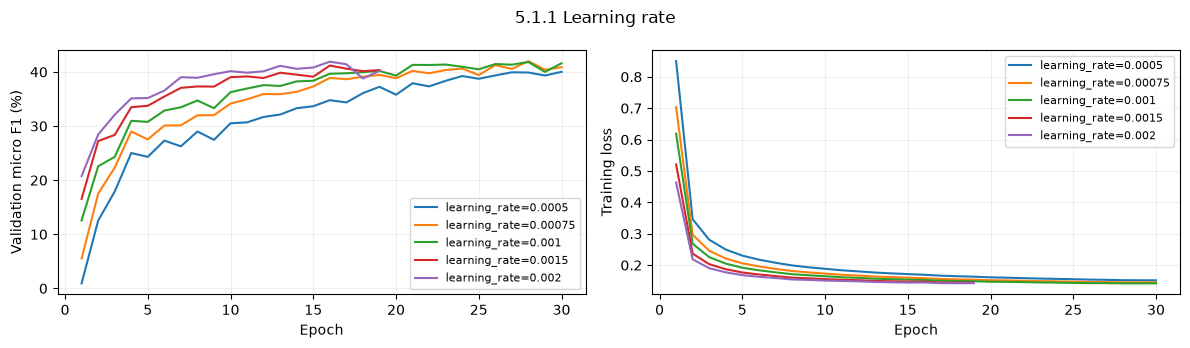

In [15]:
# Search the head learning rate with all other settings fixed
search_stage(E1_STATE, '5.1.1 Learning rate', [
    replace(E1_CONFIG, learning_rate=rate)
    for rate in (5e-4, 7.5e-4, 1e-3, 1.5e-3, 2e-3)
])


#### 5.1.2 Dropout

Use the selected learning rate and compare dropout `0.0`, `0.1`, `0.2`.
The incumbent 0.1 is listed first so exact ties retain the current choice.


,Trial,dropout,Best epoch,Epochs,Validation F1 %,Train s,Validation s
0,1,0.1,28,30,42.001,21.377,4.552
1,2,0.0,23,26,40.996,18.512,3.906
2,3,0.2,21,24,39.002,17.165,3.603


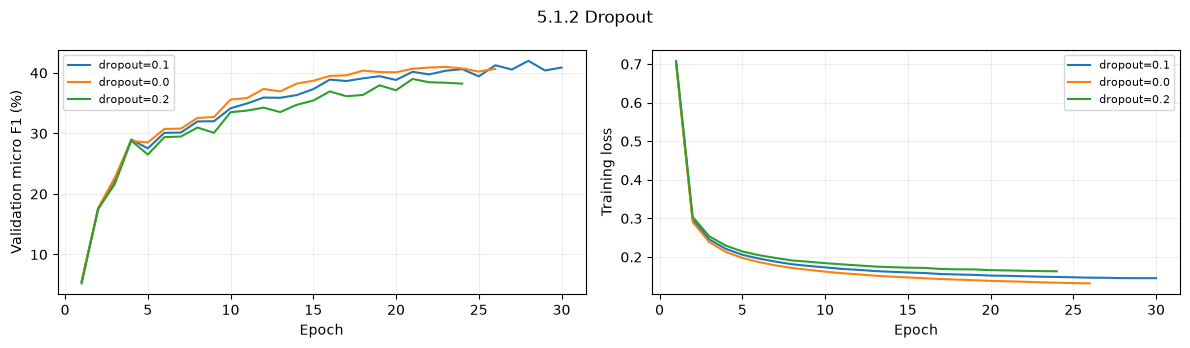

In [16]:
# Search classification head dropout with the selected learning rate
search_stage(E1_STATE, '5.1.2 Dropout', [
    replace(E1_STATE['selected'], dropout=value) for value in (0.1, 0.0, 0.2)
])


#### 5.1.3 Loss and scheduler

Compare CrossEntropy and inverse-frequency Weighted CrossEntropy using Training tokens
only. Then retain the selected loss and compare Constant, Linear decay and Linear decay
with 10% warmup. Linear schedules use the full epoch budget and may stop early.


,Trial,loss,Best epoch,Epochs,Validation F1 %,Train s,Validation s
0,1,cross_entropy,28,30,42.001,21.386,4.538
1,2,weighted_cross_entropy,17,20,17.383,14.246,3.028


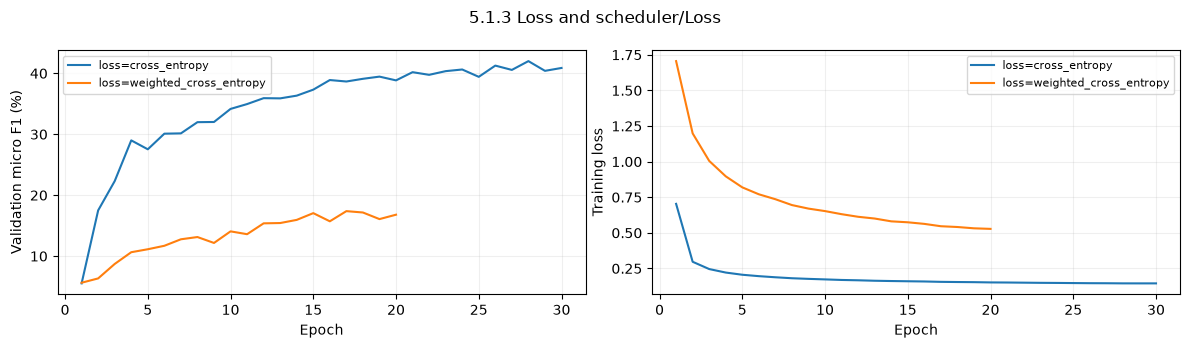

,Trial,scheduler,Best epoch,Epochs,Validation F1 %,Train s,Validation s
0,1,constant,28,30,42.001,21.396,4.567
1,2,linear,24,27,38.240,19.242,3.992
2,3,linear_warmup,24,27,37.718,19.258,4.017


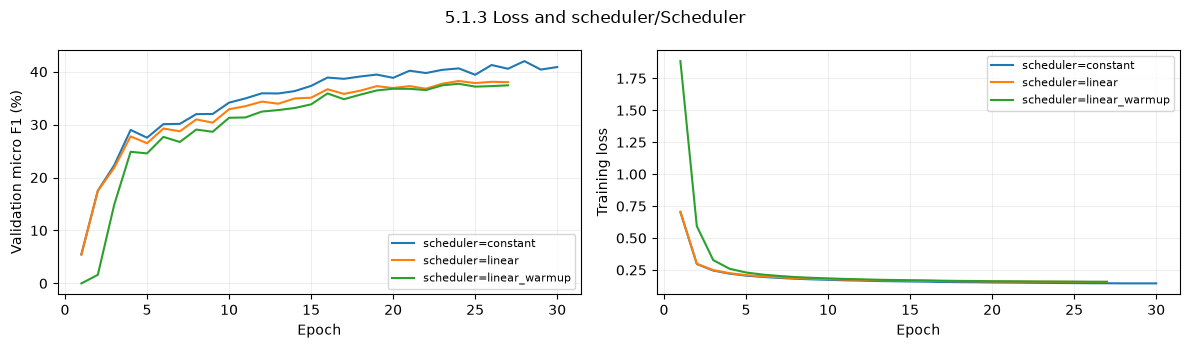

In [17]:
# Select the loss before searching the scheduler
search_stage(E1_STATE, '5.1.3 Loss and scheduler/Loss', [
    replace(E1_STATE['selected'], loss=value)
    for value in ('cross_entropy', 'weighted_cross_entropy')
])
search_stage(E1_STATE, '5.1.3 Loss and scheduler/Scheduler', [
    replace(E1_STATE['selected'], scheduler=value)
    for value in ('constant', 'linear', 'linear_warmup')
])


#### 5.1.4 Batch size and weight decay

Compare batch sizes 8, 16 and 32. Search weight decay 0, 0.01 and 0.05 only if batch
size 16 or 32 improves Validation micro F1 over the preceding batch-8 baseline.
Set `RUN_E1_STAGE4 = False` before the setup cell to omit this optional stage.


,Trial,batch_size,Best epoch,Epochs,Validation F1 %,Train s,Validation s
0,1,8,28,30,42.001,21.395,4.555
1,2,16,24,27,39.179,16.309,3.996
2,3,32,29,30,34.907,17.465,4.365


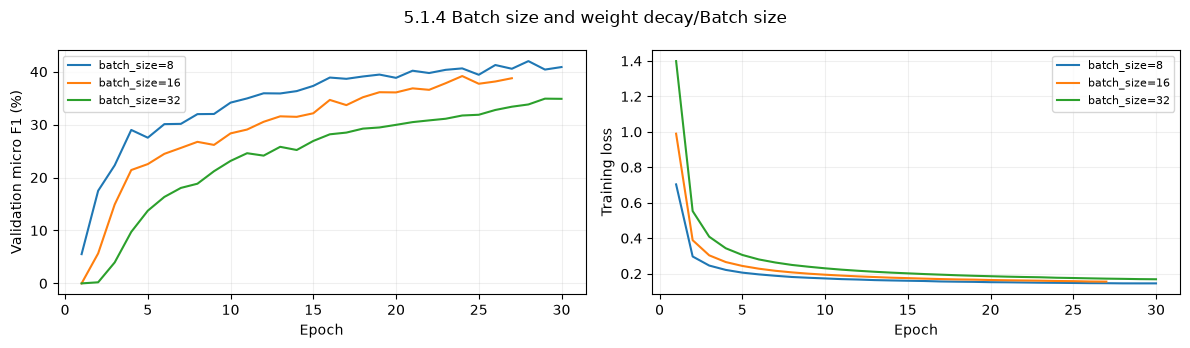

,Weight decay search,Reason
0,Skipped,No batch size improvement


In [18]:
# Continue to weight decay only when batch size improves validation F1
run_e1_optional_stage(E1_STATE)


#### 5.1.5 Three seeds and final results

Lock the selected configuration, train independent seeds 42, 9444 and 2026, and select
each checkpoint using Validation only. Then evaluate all three on Test. Report means
and sample standard deviations with `ddof=1`, including training time.


,Split,Seed,Precision %,Recall %,Micro F1 %,Macro F1 %,Train s
0,Validation,42,35.03,49.94,41.17,31.72,21.4
1,Test,42,35.18,53.02,42.29,28.97,21.4
2,Validation,9444,35.60,51.21,42.00,33.11,21.4
3,Test,9444,37.59,55.83,44.93,30.89,21.4
4,Validation,2026,34.64,50.70,41.16,31.13,20.7
5,Test,2026,36.04,55.10,43.57,28.37,20.7
6,Validation,Mean ± SD,35.09 ± 0.49,50.61 ± 0.64,41.44 ± 0.48,31.98 ± 1.02,21.2 ± 0.4
7,Test,Mean ± SD,36.27 ± 1.22,54.65 ± 1.46,43.60 ± 1.32,29.41 ± 1.32,21.2 ± 0.4


,Type,Validation F1 %,Test F1 %
0,SpecificDisease,49.26 ± 0.51,50.76 ± 1.76
1,DiseaseClass,23.74 ± 1.00,17.95 ± 0.79
2,CompositeMention,15.02 ± 2.40,3.00 ± 2.99
3,Modifier,39.92 ± 1.29,45.94 ± 1.93


,Setting,Selected value
0,learning_rate,0.00075
1,dropout,0.1
2,loss,cross_entropy
3,scheduler,constant
4,batch_size,8
5,weight_decay,0.01


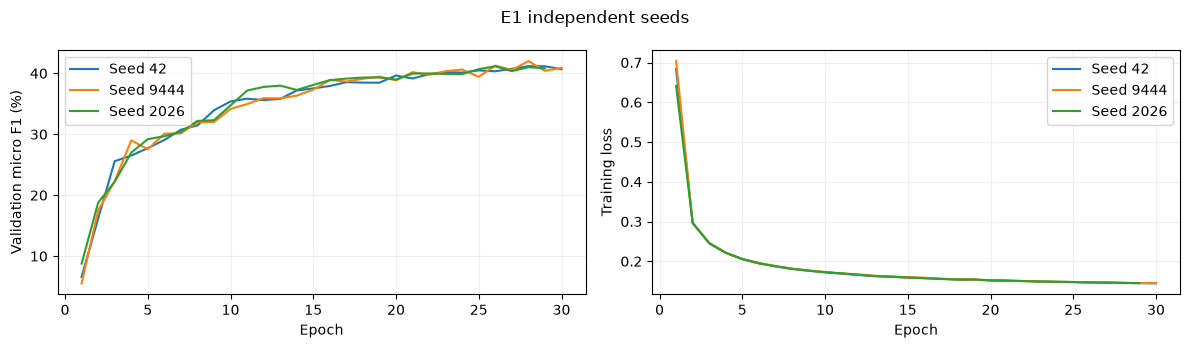

In [19]:
# Train independent seeds before accessing the Test split
E1_RESULTS = finish_experiment(E1_STATE, '5.1.5 Seeds and final results')


### 5.2 E2 — Partial fine-tuning

Freeze embeddings and Transformer layers 0–7. Train layers 8–11 and the typed-BIO head.
This run inherits the batch size, dropout, weight decay, loss, scheduler, patience,
window settings and initial head learning rate selected by E1 in this notebook run.
The inherited values are shown below and may differ from earlier script results.


In [20]:
@dataclass(frozen=True)
class E2Config:
    root: Path = project_dir
    output_dir: Path = field(default_factory=lambda: Path('results/completed/5. fine-tune/5.2 E2') /
                             datetime.now(ZoneInfo('Australia/Sydney')).strftime('run_%Y%m%d_%H%M%S_%f'))
    e1_config_path: Path | None = None
    model: str = 'dmis-lab/biobert-base-cased-v1.1'
    epochs: int = 30
    batch_size: int = 8
    weight_decay: float = 0.01
    scheduler: str = 'constant'
    patience: int = 3
    loss: str = 'cross_entropy'
    seed: int = 9444
    dropout: float = 0.1
    encoder_learning_rate: float = 1e-5
    head_learning_rate: float = 7.5e-4
    max_length: int = 512
    stride: int = 64
    micro_batch_size: int = 8
    cuda_fast_mode: bool = True
    cuda_evaluation_batch_size: int = 32
    limit_docs: int | None = None
    evaluate_test: bool = True

# Configure e2
def configure_e2(model, encoder_learning_rate=2e-5, head_learning_rate=1e-4):
    """Fix E2 to four trainable layers and create disjoint optimizer groups."""
    layers = model.base_model.encoder.layer
    if len(layers) != 12:
        raise ValueError('E2 requires the 12-layer BioBERT backbone')
    for parameter in model.parameters():
        parameter.requires_grad = False
    encoder_parameters = []
    for layer in layers[8:12]:
        for parameter in layer.parameters():
            parameter.requires_grad = True
            encoder_parameters.append(parameter)
    head_parameters = list(model.classifier.parameters())
    for parameter in head_parameters:
        parameter.requires_grad = True
    expected = {id(p) for p in encoder_parameters + head_parameters}
    actual = {id(p) for p in model.parameters() if p.requires_grad}
    if actual != expected or len(expected) != len(encoder_parameters) + len(head_parameters):
        raise ValueError('E2 parameter groups must cover the trainable parameters exactly once')
    return [
        {'params': encoder_parameters, 'lr': encoder_learning_rate},
        {'params': head_parameters, 'lr': head_learning_rate},
    ]


# Set e2 training mode
def set_e2_training_mode(model):
    """Enable dropout in the trainable layers/head, keep the frozen prefix in eval."""
    model.train()
    model.base_model.embeddings.eval()
    for layer in model.base_model.encoder.layer[:8]:
        layer.eval()


# Execution batch sizes
def execution_batch_sizes(config, device):
    if device.type == 'cuda':
        return config.micro_batch_size, config.cuda_evaluation_batch_size
    return min(config.micro_batch_size, 2), min(config.micro_batch_size, 2)


# Evaluate e2
def evaluate_e2(model, records, windows, batch_size, collate, amp_dtype=None):
    import torch
    from torch.utils.data import DataLoader

    model.eval()
    sums = [torch.zeros((len(record['input_ids']), len(LABELS))) for record in records]
    counts = [torch.zeros(len(record['input_ids'])) for record in records]
    votes = [{} for _ in records]
    with torch.no_grad():
        for batch, inputs in DataLoader(windows, batch_size=batch_size, collate_fn=collate):
            inputs.pop('labels')
            with precision_context(inputs['input_ids'].device, amp_dtype):
                logits = model(**inputs).logits.float().cpu()
            for row, window in enumerate(batch):
                doc, start, end = window['doc'], window['start'], window['end']
                values = logits[row, 1:1 + end - start]
                sums[doc][start:end] += values
                counts[doc][start:end] += 1
                for position, label in enumerate(values.argmax(-1).tolist(), start):
                    votes[doc].setdefault(position, set()).add(label)
            del logits, inputs
    predictions, illegal, conflicts = [], 0, 0
    for record, total, count, doc_votes in zip(records, sums, counts, votes):
        if not (count > 0).all():
            raise ValueError('Uncovered document tokens')
        prediction, bad = decode_document(record, (total / count[:, None]).argmax(-1))
        predictions.append(prediction)
        illegal += bad
        conflicts += sum(len(labels) > 1 for labels in doc_votes.values())
    metrics = evaluate_standardized_records(records, predictions)
    metrics.update(illegal_bio_transitions=illegal, window_overlap_token_conflicts=conflicts)
    return metrics, predictions


# Backward e2 batch
def backward_e2_batch(model, inputs, weights, micro_batch_size, amp_dtype=None, return_tensors=False):
    import torch
    from torch.nn.functional import cross_entropy

    labels = inputs['labels']
    valid = labels != -100
    denominator = (weights[labels.clamp_min(0)] * valid).sum() if weights is not None else valid.sum()
    numerator = torch.zeros((), device=labels.device, dtype=torch.float32)
    for start in range(0, labels.shape[0], micro_batch_size):
        targets = labels[start:start + micro_batch_size]
        chunk = {key: value[start:start + micro_batch_size] for key, value in inputs.items() if key != 'labels'}
        with precision_context(labels.device, amp_dtype):
            logits = model(**chunk).logits
            loss_sum = cross_entropy(logits.reshape(-1, len(LABELS)), targets.reshape(-1),
                                     weight=weights, ignore_index=-100, reduction='sum')
            loss = loss_sum / denominator
        loss.backward()
        numerator += loss_sum.detach()
        del logits, loss_sum, loss, chunk
    if return_tensors:
        return numerator, denominator.detach()
    return numerator.item(), denominator.item()


# Snapshot trainable parameters
def snapshot_trainable_parameters(model):
    return {name: parameter.detach().to('cpu', copy=True) for name, parameter in model.named_parameters()
            if parameter.requires_grad}


# Restore trainable checkpoint
def restore_trainable_checkpoint(model, path):
    import torch

    state = torch.load(path, map_location='cpu', weights_only=True)
    expected = {name for name, parameter in model.named_parameters() if parameter.requires_grad}
    if set(state) != expected:
        raise ValueError('E2 checkpoint does not match the trainable parameter scope')
    model.load_state_dict(state, strict=False)

# Use the shared padded collator
make_e2_collator = make_collator

# Train one independent E2 configuration
def e2_train_trial(config, output_dir, data):
    import random
    import numpy as np
    import torch
    from torch.utils.data import DataLoader
    from transformers import AutoModelForTokenClassification, BertConfig

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=False)
    pass

    random.seed(config.seed)
    np.random.seed(config.seed)
    torch.manual_seed(config.seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(config.seed)
    tokenizer, train_records, train_windows, valid_records, valid_windows = data
    device = torch.device('cuda') if torch.cuda.is_available() else choose_training_device(torch)
    amp_dtype = configure_runtime(config, device)
    micro_batch_size, evaluation_batch_size = execution_batch_sizes(config, device)
    model_config = BertConfig.from_pretrained(
        config.model, num_labels=len(LABELS), classifier_dropout=config.dropout,
        id2label=dict(enumerate(LABELS)), label2id={label: index for index, label in enumerate(LABELS)})
    model = AutoModelForTokenClassification.from_pretrained(
        config.model, config=model_config, **({'attn_implementation': 'sdpa'} if device.type == 'cuda' and config.cuda_fast_mode else {}))
    groups = configure_e2(model, config.encoder_learning_rate, config.head_learning_rate)
    if config.max_length > model.config.max_position_embeddings:
        raise ValueError('Window length exceeds model position embeddings')
    model.to(device)
    trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
    optimizer = torch.optim.AdamW(groups, weight_decay=config.weight_decay,
                                  **({'fused': True} if device.type == 'cuda' and config.cuda_fast_mode else {}))
    total_steps = math.ceil(len(train_windows) / config.batch_size) * config.epochs
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: learning_rate_factor(step, total_steps, config.scheduler))
    weights = training_class_weights(train_windows, torch).to(device) if config.loss == 'weighted_cross_entropy' else None
    collate = make_e2_collator(tokenizer, device, align=device.type == 'cuda' and config.cuda_fast_mode)
    loader = DataLoader(train_windows, batch_size=config.batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(config.seed), collate_fn=collate)
    metadata = asdict(config)
    metadata.update(device=str(device),
                    gpu_name=torch.cuda.get_device_name(device) if device.type == 'cuda' else None,
                    amp_dtype=str(amp_dtype), actual_micro_batch_size=micro_batch_size,
                    evaluation_batch_size=evaluation_batch_size,
                    attention_implementation=model.config._attn_implementation,
                    deterministic_algorithms=torch.are_deterministic_algorithms_enabled(),
                    cuda_version=torch.version.cuda, trainable_parameters=sum(p.numel() for p in trainable),
                    train_documents=len(train_records), validation_documents=len(valid_records),
                    trainable_layers=[8, 9, 10, 11], labels=LABELS,
                    class_weights=weights.cpu().tolist() if weights is not None else None,
                    torch_version=torch.__version__,
                    implementation='inline notebook')
    save_json(output_dir / 'config.json', metadata)
    pass


    synchronize_device(torch, device)
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(device)
    started = time.perf_counter()
    best_f1, stale, history = -1.0, 0, []
    training_seconds, validation_seconds = 0.0, 0.0
    best_state = None
    try:
        for epoch in range(1, config.epochs + 1):
            epoch_started = time.perf_counter()
            set_e2_training_mode(model)
            numerator = torch.zeros((), device=device)
            denominator = torch.zeros((), device=device)
            rates = [group['lr'] for group in optimizer.param_groups]
            for _, inputs in loader:
                optimizer.zero_grad(set_to_none=True)
                loss_sum, count = backward_e2_batch(model, inputs, weights, micro_batch_size, amp_dtype, return_tensors=True)
                torch.nn.utils.clip_grad_norm_(trainable, 1.0)
                optimizer.step()
                scheduler.step()
                numerator += loss_sum
                denominator += count
                del inputs
            optimizer.zero_grad(set_to_none=True)
            synchronize_device(torch, device)
            training_loss = (numerator / denominator).item()
            train_time = time.perf_counter() - epoch_started
            validation_started = time.perf_counter()
            metrics, predictions = evaluate_e2(model, valid_records, valid_windows, evaluation_batch_size, collate, amp_dtype)
            synchronize_device(torch, device)
            valid_time = time.perf_counter() - validation_started
            training_seconds += train_time
            validation_seconds += valid_time
            f1 = metrics['typed_exact']['f1']
            history.append({'epoch': epoch, 'training_loss': training_loss, 'validation_f1': f1,
                            'encoder_learning_rate': rates[0], 'head_learning_rate': rates[1],
                            'training_seconds': train_time, 'validation_seconds': valid_time})
            if f1 > best_f1:
                best_f1, best_epoch, stale = f1, epoch, 0
                best_metrics = metrics
                best_state = snapshot_trainable_parameters(model)
                save_json(output_dir / 'validation_metrics.json', metrics)
                save_json(output_dir / 'validation_predictions.json', predictions)
            else:
                stale += 1
            save_json(output_dir / 'history.json', history)
            report_epoch(epoch, config.epochs, training_loss, f1, best_f1)
            pass



            if device.type == 'mps':
                release_device_memory(torch, device)
            if stale >= config.patience:
                pass
                break
        torch.save(best_state, output_dir / 'best_trainable.pt')
        result = {'config': asdict(config), 'path': str(output_dir.resolve()),
                  'validation_f1': best_f1, 'validation': best_metrics, 'best_epoch': best_epoch,
                  'epochs_run': len(history), 'training_seconds': training_seconds,
                  'peak_gpu_memory_bytes': torch.cuda.max_memory_allocated(device) if device.type == 'cuda' else None,
                  'validation_seconds': validation_seconds,
                  'training_validation_wall_seconds': time.perf_counter() - started}
        save_json(output_dir / 'summary.json', result)
        return result
    except BaseException as error:
        save_json(output_dir / 'failure.json', {'error': repr(error), 'elapsed_seconds': time.perf_counter() - started})
        raise
    finally:
        del model, optimizer, scheduler, groups, trainable, loader, weights
        release_device_memory(torch, device)

# Reload all trainable E2 layers
def e2_evaluate_final_trial(config, trial, tokenizer, test_data):
    import torch
    from transformers import AutoModelForTokenClassification, BertConfig

    device = torch.device('cuda') if torch.cuda.is_available() else choose_training_device(torch)
    amp_dtype = configure_runtime(config, device)
    _, evaluation_batch_size = execution_batch_sizes(config, device)
    model_config = BertConfig.from_pretrained(
        config.model, num_labels=len(LABELS), classifier_dropout=config.dropout,
        id2label=dict(enumerate(LABELS)), label2id={label: index for index, label in enumerate(LABELS)})
    model = AutoModelForTokenClassification.from_pretrained(
        config.model, config=model_config, **({'attn_implementation': 'sdpa'} if device.type == 'cuda' and config.cuda_fast_mode else {}))
    configure_e2(model, config.encoder_learning_rate, config.head_learning_rate)
    restore_trainable_checkpoint(model, Path(trial['path']) / 'best_trainable.pt')
    model.to(device)
    synchronize_device(torch, device)
    started = time.perf_counter()
    try:
        metrics, predictions = evaluate_e2(model, *test_data, evaluation_batch_size,
            make_e2_collator(tokenizer, device, align=device.type == 'cuda' and config.cuda_fast_mode), amp_dtype)
        synchronize_device(torch, device)
        seconds = time.perf_counter() - started
        save_json(Path(trial['path']) / 'test_metrics.json', metrics)
        save_json(Path(trial['path']) / 'test_predictions.json', predictions)
        pass
        return {'seed': config.seed, 'metrics': metrics, 'test_seconds': seconds}
    finally:
        del model
        release_device_memory(torch, device)

In [21]:
# Inherit the new E1 selection from memory without external result files
if not E1_STATE.get('complete'):
    raise RuntimeError('Run all E1 stages before setting up E2')
e1_selected = E1_STATE['selected']
inherited_keys = ('model', 'epochs', 'batch_size', 'weight_decay', 'scheduler',
                  'patience', 'loss', 'dropout', 'max_length', 'stride')
E2_CONFIG = E2Config(
    root=project_dir,
    **{key: getattr(e1_selected, key) for key in inherited_keys},
    head_learning_rate=e1_selected.learning_rate,
    e1_config_path=E1_STATE['output_dir'] / 'selected_config.json',
    cuda_fast_mode=CUDA_FAST_MODE,
    limit_docs=2 if SMOKE_TEST else None,
    evaluate_test=not SMOKE_TEST,
)
E2_STATE = prepare_experiment('E2', E2_CONFIG, e2_train_trial, e2_evaluate_final_trial)
display(pd.DataFrame([
    {'Setting': key, 'Inherited value': getattr(E2_CONFIG, key)}
    for key in (*inherited_keys, 'head_learning_rate')
]))


,Setting,Inherited value
0,model,dmis-lab/biobert-base-cased-v1.1
1,epochs,30
2,batch_size,8
3,weight_decay,0.01
4,scheduler,constant
5,patience,3
6,loss,cross_entropy
7,dropout,0.1
8,max_length,512
9,stride,64


#### 5.2.1 Encoder learning rate

Compare Encoder LR `1e-5`, `2e-5`, `3e-5` with seed 9444 and the E1-selected Head LR.


,Trial,encoder_learning_rate,Best epoch,Epochs,Validation F1 %,Train s,Validation s
0,1,1e-05,13,16,65.380,20.390,2.294
1,2,2e-05,12,15,68.969,19.079,2.148
2,3,3e-05,10,13,70.616,16.525,1.895


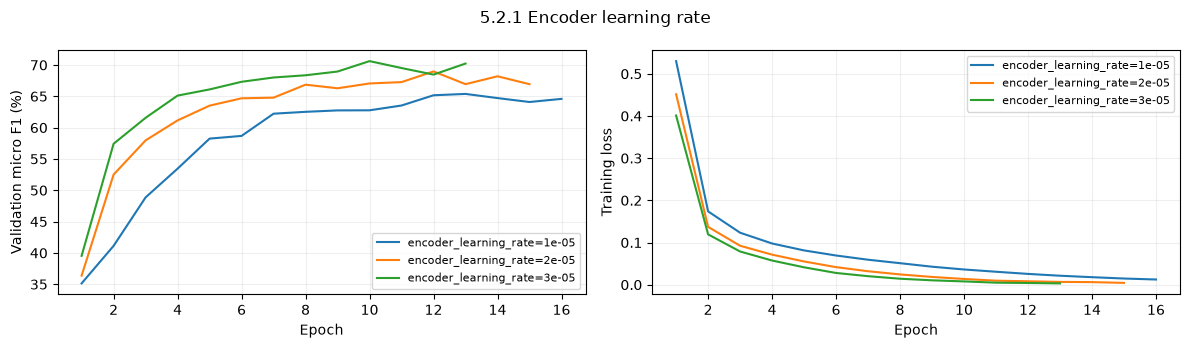

In [22]:
# Search encoder learning rates using the inherited head learning rate
search_stage(E2_STATE, '5.2.1 Encoder learning rate', [
    replace(E2_CONFIG, encoder_learning_rate=rate) for rate in (1e-5, 2e-5, 3e-5)
])


#### 5.2.2 Head learning rate

Keep the selected Encoder LR and compare Head LR `5e-5`, `1e-4`, `2e-4`.


,Trial,head_learning_rate,Best epoch,Epochs,Validation F1 %,Train s,Validation s
0,1,5e-05,12,15,72.172,19.054,2.172
1,2,0.0001,7,10,71.096,12.725,1.491
2,3,0.0002,7,10,71.311,12.745,1.498


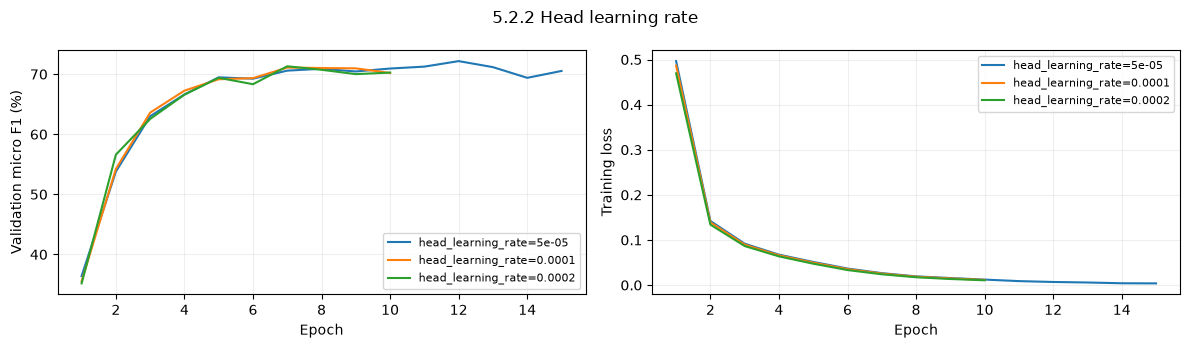

In [23]:
# Search the requested head learning rates with the best encoder rate
search_stage(E2_STATE, '5.2.2 Head learning rate', [
    replace(E2_STATE['selected'], head_learning_rate=rate) for rate in (5e-5, 1e-4, 2e-4)
])


#### 5.2.3 Three seeds and final results

Lock both learning rates and repeat seeds 42, 9444 and 2026. Select checkpoints on
Validation, then evaluate all three on Test and report mean ± sample standard deviation.


,Split,Seed,Precision %,Recall %,Micro F1 %,Macro F1 %,Train s
0,Validation,42,67.27,75.98,71.36,63.95,15.3
1,Test,42,64.04,76.04,69.52,56.95,15.3
2,Validation,9444,68.09,76.75,72.16,65.51,19.0
3,Test,9444,69.95,80.00,74.64,62.06,19.0
4,Validation,2026,66.02,78.27,71.63,64.06,20.4
5,Test,2026,66.87,80.10,72.89,60.87,20.4
6,Validation,Mean ± SD,67.13 ± 1.04,77.00 ± 1.16,71.72 ± 0.41,64.51 ± 0.87,18.2 ± 2.7
7,Test,Mean ± SD,66.95 ± 2.96,78.72 ± 2.32,72.35 ± 2.60,59.96 ± 2.68,18.2 ± 2.7


,Type,Validation F1 %,Test F1 %
0,SpecificDisease,77.81 ± 0.46,75.36 ± 2.81
1,DiseaseClass,52.07 ± 1.01,49.49 ± 3.60
2,CompositeMention,52.62 ± 3.07,32.37 ± 3.29
3,Modifier,75.53 ± 0.49,82.63 ± 1.38


,Setting,Selected value
0,encoder_learning_rate,0.00003
1,head_learning_rate,0.00005
2,dropout,0.1
3,loss,cross_entropy
4,scheduler,constant
5,batch_size,8
6,weight_decay,0.01


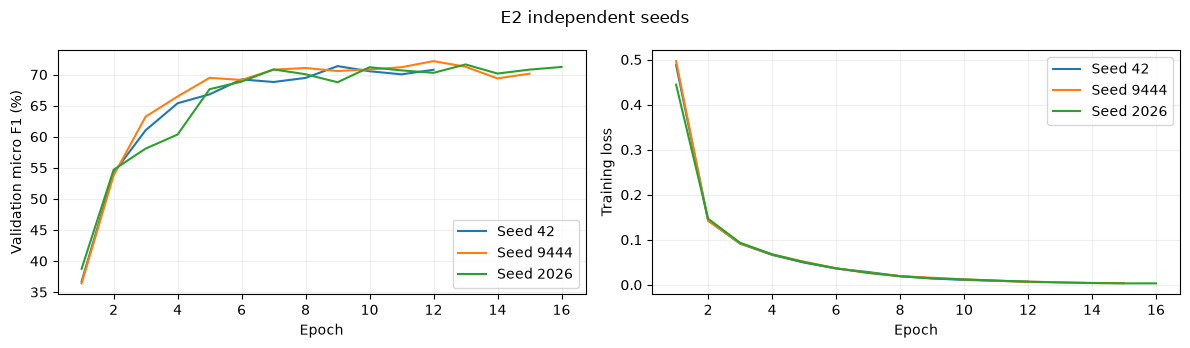

,Experiment,Validation micro F1 %,Test micro F1 %,Train s
0,E1,41.44 ± 0.48,43.60 ± 1.32,21.2 ± 0.4
1,E2,71.72 ± 0.41,72.35 ± 2.60,18.2 ± 2.7


In [24]:
# Complete the independent seeds and final evaluation
E2_RESULTS = finish_experiment(E2_STATE, '5.2.3 Seeds and final results')
display_experiment_comparison(E1_RESULTS, E2_RESULTS)
